# POC TATAP: Cabang Pandangan dan Arsitektur Multimodal Late Fusion

**Datathon RISTEK Fasilkom UI 2026, Preliminary Round (University Track)**

---

## Tujuan notebook ini

Notebook ini memisahkan dua tingkat bukti:

1. **POC empiris cabang pandangan.** Menjawab apakah geometri scanpath memuat sinyal yang dapat
   dijelaskan dan dievaluasi secara jujur untuk triase ASD.
2. **Implementasi arsitektur produk multimodal.** TATAP merencanakan model pandangan,
   kepala/wajah, dan vokalisasi yang terpisah, kemudian menggabungkan probabilitas
   terkalibrasi memakai quality-aware weighted late fusion.

Empat hal yang ingin ditunjukkan:

1. **Sinyal pandangan nyata dan bisa dijelaskan.** Fitur geometri sederhana memisahkan ASD vs TD.
2. **Evaluasi harus ketat.** Penggelembungan akibat augmentasi dan pembagian data dilaporkan.
3. **Batas data terlihat.** Kurva belajar belum stabil, sehingga data ini belum menentukan batas
   atas performa maupun menjamin bahwa penambahan data otomatis memperbaikinya.
4. **Fusion dirancang tanpa klaim palsu.** Cabang multimodal dan manfaat fusion baru boleh dinilai
   pada data prospektif berpasangan dari anak dan sesi yang sama.

## Yang TIDAK diklaim notebook ini

- **Bukan alat diagnosis.** Output adalah skor risiko untuk triase/rujukan.
- **Tidak memvalidasi skrining pada balita.** Partisipan dataset pandangan rata-rata berusia
  **7,88 tahun**; POC hanya memvalidasi prinsip geometri scanpath.
- **Bukan validasi webcam.** Data berasal dari eye-tracker laboratorium, bukan kamera tablet.
- **Bukan populasi Indonesia.** Partisipan dan stimulus berasal dari Prancis.
- **Belum ada metrik multimodal.** Dataset multimodal yang tersedia bersifat sintetis dan tidak
  dipakai untuk klaim akurasi, kalibrasi, atau manfaat fusion.

## Peta isi

| Bagian | Isi |
|---|---|
| 0 | Lingkungan & dependensi |
| 1 | Dataset pandangan: sumber, struktur, komposisi |
| 2 | Ekstraksi fitur |
| 3 | Exploratory Data Analysis |
| 4 | Demonstrasi kebocoran data |
| 5 | Hasil utama cabang pandangan |
| 6 | Kurva belajar |
| 7 | Interpretabilitas |
| 8 | Kesimpulan POC pandangan |
| 9 | Arsitektur multimodal dan protokol late fusion |


## 0. Lingkungan

Notebook ini dirancang memakai virtual environment yang **sudah ada**:

```
/Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/.venv
```

Folder `.vscode/settings.json` di project ini sudah mengarahkan VS Code ke interpreter tersebut.
Kalau kernel belum terdeteksi, jalankan sekali: `bash setup_kernel.sh`, lalu pilih kernel
**Dataton (.venv)**.

Paket yang dibutuhkan: `numpy`, `pandas`, `pillow`, `scikit-learn`, `matplotlib`.

In [2]:
import sys, platform
from pathlib import Path

print("Python    :", sys.version.split()[0], f"({platform.system()})")
print("Executable:", sys.executable)

EXPECTED_VENV = "Kuliah & Coding/.venv"
print("\n[OK] Memakai venv yang diharapkan." if EXPECTED_VENV in sys.executable else
      f"\n[INFO] Bukan venv target ('{EXPECTED_VENV}'). Notebook tetap jalan selama paket tersedia,\n"
      "       tapi untuk konsistensi pilih interpreter .venv lewat pemilih kernel.")

Python    : 3.11.6 (Darwin)
Executable: /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/.venv/bin/python

[OK] Memakai venv yang diharapkan.


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import gridspec
from PIL import Image

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, average_precision_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False,
    "axes.spines.right": False, "figure.facecolor": "white",
})
C_TD, C_ASD = "#2A6F97", "#C1440E"
PAL = {"TD": C_TD, "ASD": C_ASD}

import sklearn
for nm, m in [("numpy", np), ("pandas", pd), ("sklearn", sklearn)]:
    print(f"{nm:10s} {m.__version__}")

numpy      2.4.6
pandas     3.0.3
sklearn    1.8.0


## 1. Dataset

**Sumber:** [Autism Eye Tracking, Kaggle (aqilamalfa)](https://www.kaggle.com/datasets/aqilamalfa/autism-eye-tracking)

**Sumber asli / sitasi primer:** Carette, R., Elbattah, M., Cilia, F., Dequen, G., Guérin, J.-L., & Bosche, J.
(2019). *Learning to Predict Autism Spectrum Disorder based on the Visual Patterns of Eye-tracking Scanpaths.*
Proceedings of BIOSTEC 2019 (HEALTHINF), pp. 103–112. DOI: 10.5220/0007402601030112

### Cara data ini dibuat

Rekaman eye-tracker mentah (koordinat gaze x, y terhadap waktu) dirender menjadi citra 640×480.
Yang penting dipahami: **warna bukan dekorasi, tapi membawa informasi dinamika gerakan mata.**

| Kanal | Makna fisik |
|---|---|
| **R (merah)** | Kecepatan (*velocity*) gerakan mata |
| **G (hijau)** | Akselerasi |
| **B (biru)** | *Jerk* (turunan akselerasi) |

Konsekuensinya:

- **Fiksasi → tampak cyan** (velocity rendah, akselerasi dan jerk tinggi), yaitu momen mata berhenti mengamati
- **Sakade → tampak kuning/putih** (velocity tinggi; putih = melampaui batas cap), yaitu lompatan cepat antar titik

Karena itu statistik per kanal warna **punya arti fisik langsung**, bukan sekadar angka piksel.
Inilah yang memungkinkan model kami tetap interpretable.

### Struktur berkas

Pola nama `T{C,S}###_PP.png`:

- `TC` = *typically developing* (kontrol), `TS` = ASD
- `###` = indeks rekaman
- **`PP` = ID partisipan** ← inilah kunci untuk mencegah kebocoran data

In [4]:
NB_DIR = Path.cwd()
DATA_DIR = None
for cand in [NB_DIR, NB_DIR.parent, NB_DIR.parent.parent]:
    p = cand / "data" / "autism eye tracking dataset"
    if p.exists():
        DATA_DIR = p; break
if DATA_DIR is None:
    raise FileNotFoundError(
        "Folder 'data/autism eye tracking dataset' tidak ditemukan.\n"
        f"Notebook dijalankan dari: {NB_DIR}\n"
        "Pastikan notebook berada di folder project yang sama dengan dataset.")
print("Dataset:", DATA_DIR)

records = []
for label, sub, prefix in [(0, "TCImages", "TC"), (1, "TSImages", "TS")]:
    for f in sorted((DATA_DIR / sub).glob("*.png")):
        pid = f.stem.split("_")[1]
        records.append({"path": f, "file": f.name, "label": label,
                        "group": "TD" if label == 0 else "ASD",
                        "participant": f"{prefix}{pid}"})
meta = pd.DataFrame(records)
print(f"\nTotal citra      : {len(meta)}")
print(f"Total partisipan : {meta.participant.nunique()}")

Dataset: /Users/timotiuspatrick/Documents/Patrick/Kuliah & Coding/Dataton/project/autism eye tracking dataset

Total citra      : 547
Total partisipan : 54


In [5]:
summary = (meta.groupby("group")
           .agg(n_citra=("file", "size"), n_partisipan=("participant", "nunique"))
           .assign(citra_per_partisipan=lambda d: (d.n_citra / d.n_partisipan).round(1)))
summary.loc["TOTAL"] = [len(meta), meta.participant.nunique(),
                        round(len(meta) / meta.participant.nunique(), 1)]
display(summary)

per_p = meta.groupby(["group", "participant"]).size().rename("n_citra").reset_index()
print("\nDistribusi jumlah citra per partisipan:")
display(per_p.groupby("group").n_citra.describe()[["min","25%","50%","75%","max"]].round(1))
print(f"\nProporsi kelas ASD: {meta.label.mean():.1%}  (dataset tidak seimbang)")

,n_citra,n_partisipan,citra_per_partisipan
group,,,
ASD,219.0,26.0,8.4
TD,328.0,28.0,11.7
TOTAL,547.0,54.0,10.1



Distribusi jumlah citra per partisipan:


,min,25%,50%,75%,max
group,,,,,
ASD,1.0,5.0,9.0,11.8,16.0
TD,2.0,7.0,12.0,16.0,23.0



Proporsi kelas ASD: 40.0%  (dataset tidak seimbang)


### EDA 1, Komposisi dataset

Tiga hal yang perlu dilihat sebelum apa pun: seberapa timpang kelasnya, berapa citra per anak,
dan apakah ada anak yang menyumbang jauh lebih banyak dari yang lain.

/var/folders/cg/mk19_4755fxfc3thmsh50vhm0000gn/T/ipykernel_27489/2328251204.py:35: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(); plt.show()


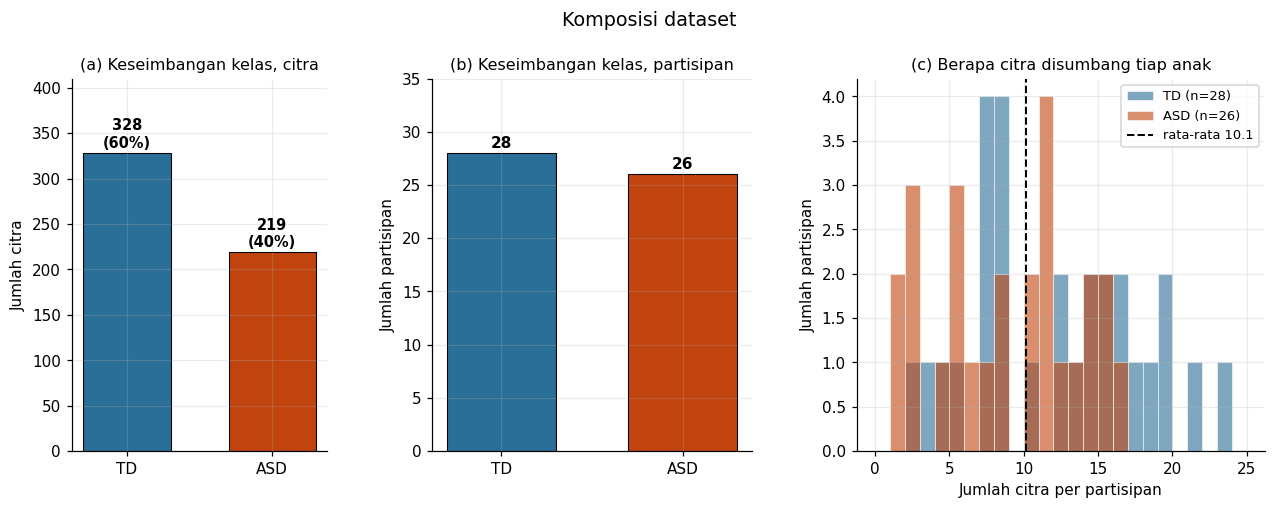

Rata-rata 10.1 citra per partisipan (rentang 1-23).
Inilah alasan split acak per-citra berbahaya: anak yang sama hampir pasti
muncul di data latih dan data uji sekaligus. Dibahas di Bagian 4.


In [6]:
fig = plt.figure(figsize=(14, 4.4))
gs = gridspec.GridSpec(1, 3, width_ratios=[1, 1.25, 1.6], wspace=0.32)

# (a) keseimbangan kelas
ax = fig.add_subplot(gs[0])
cnt = meta.group.value_counts()[["TD", "ASD"]]
b = ax.bar(cnt.index, cnt.values, color=[C_TD, C_ASD], edgecolor="black", linewidth=0.7, width=0.6)
for bar, v in zip(b, cnt.values):
    ax.text(bar.get_x()+bar.get_width()/2, v+6, f"{v}\n({v/len(meta):.0%})",
            ha="center", fontsize=9.5, fontweight="bold")
ax.set_ylabel("Jumlah citra"); ax.set_title("(a) Keseimbangan kelas, citra", fontsize=10.5)
ax.set_ylim(0, cnt.max()*1.25)

# (b) jumlah partisipan
ax = fig.add_subplot(gs[1])
pc = meta.groupby("group").participant.nunique()[["TD", "ASD"]]
b = ax.bar(pc.index, pc.values, color=[C_TD, C_ASD], edgecolor="black", linewidth=0.7, width=0.6)
for bar, v in zip(b, pc.values):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.5, str(v), ha="center", fontsize=10, fontweight="bold")
ax.set_ylabel("Jumlah partisipan"); ax.set_title("(b) Keseimbangan kelas, partisipan", fontsize=10.5)
ax.set_ylim(0, pc.max()*1.25)

# (c) sebaran citra per partisipan
ax = fig.add_subplot(gs[2])
for g in ["TD", "ASD"]:
    d = per_p[per_p.group == g].n_citra
    ax.hist(d, bins=range(0, int(per_p.n_citra.max())+3), alpha=0.6, label=f"{g} (n={len(d)})",
            color=PAL[g], edgecolor="white", linewidth=0.6)
ax.axvline(per_p.n_citra.mean(), color="black", ls="--", lw=1.3,
           label=f"rata-rata {per_p.n_citra.mean():.1f}")
ax.set_xlabel("Jumlah citra per partisipan"); ax.set_ylabel("Jumlah partisipan")
ax.set_title("(c) Berapa citra disumbang tiap anak", fontsize=10.5); ax.legend(fontsize=8.5)

plt.suptitle("Komposisi dataset", fontsize=12.5, y=1.02)
plt.tight_layout(); plt.show()

print(f"Rata-rata {per_p.n_citra.mean():.1f} citra per partisipan "
      f"(rentang {per_p.n_citra.min()}-{per_p.n_citra.max()}).")
print("Inilah alasan split acak per-citra berbahaya: anak yang sama hampir pasti")
print("muncul di data latih dan data uji sekaligus. Dibahas di Bagian 4.")

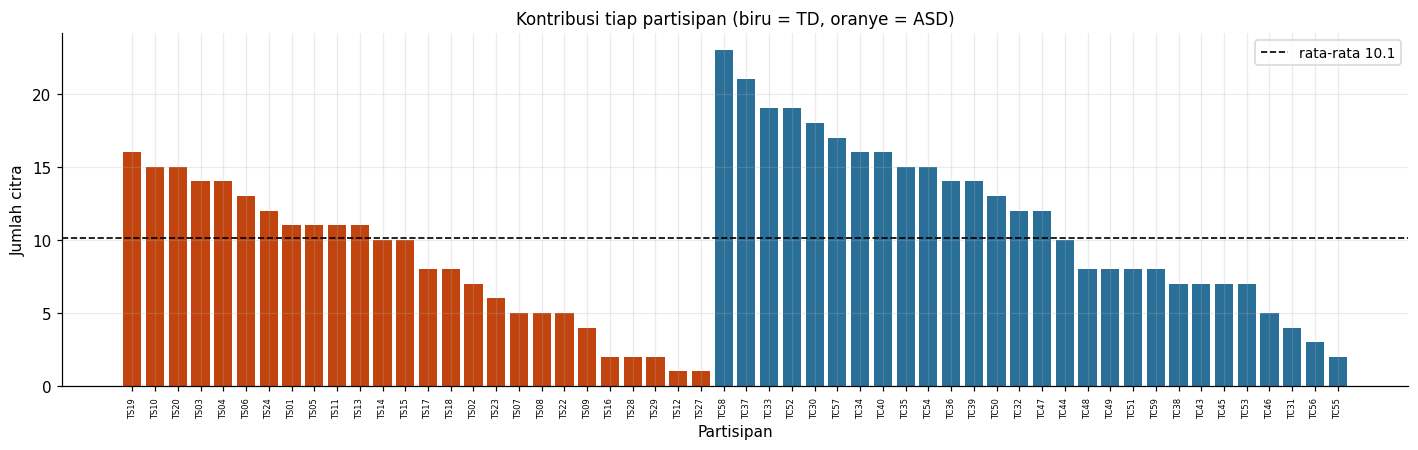

In [7]:
fig, ax = plt.subplots(figsize=(13, 4.2))
order = per_p.sort_values(["group", "n_citra"], ascending=[True, False])
cols = [PAL[g] for g in order.group]
ax.bar(range(len(order)), order.n_citra, color=cols, edgecolor="none")
ax.axhline(per_p.n_citra.mean(), color="black", ls="--", lw=1.1, label=f"rata-rata {per_p.n_citra.mean():.1f}")
ax.set_xticks(range(len(order))); ax.set_xticklabels(order.participant, rotation=90, fontsize=5.5)
ax.set_ylabel("Jumlah citra"); ax.set_xlabel("Partisipan")
ax.set_title("Kontribusi tiap partisipan (biru = TD, oranye = ASD)", fontsize=11)
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

### EDA 2, Seperti apa datanya

Citra dirender di atas latar hitam dan sangat redup. Untuk keperluan tampilan saja, kecerahannya
kami naikkan. Perhitungan fitur tetap memakai nilai piksel asli.

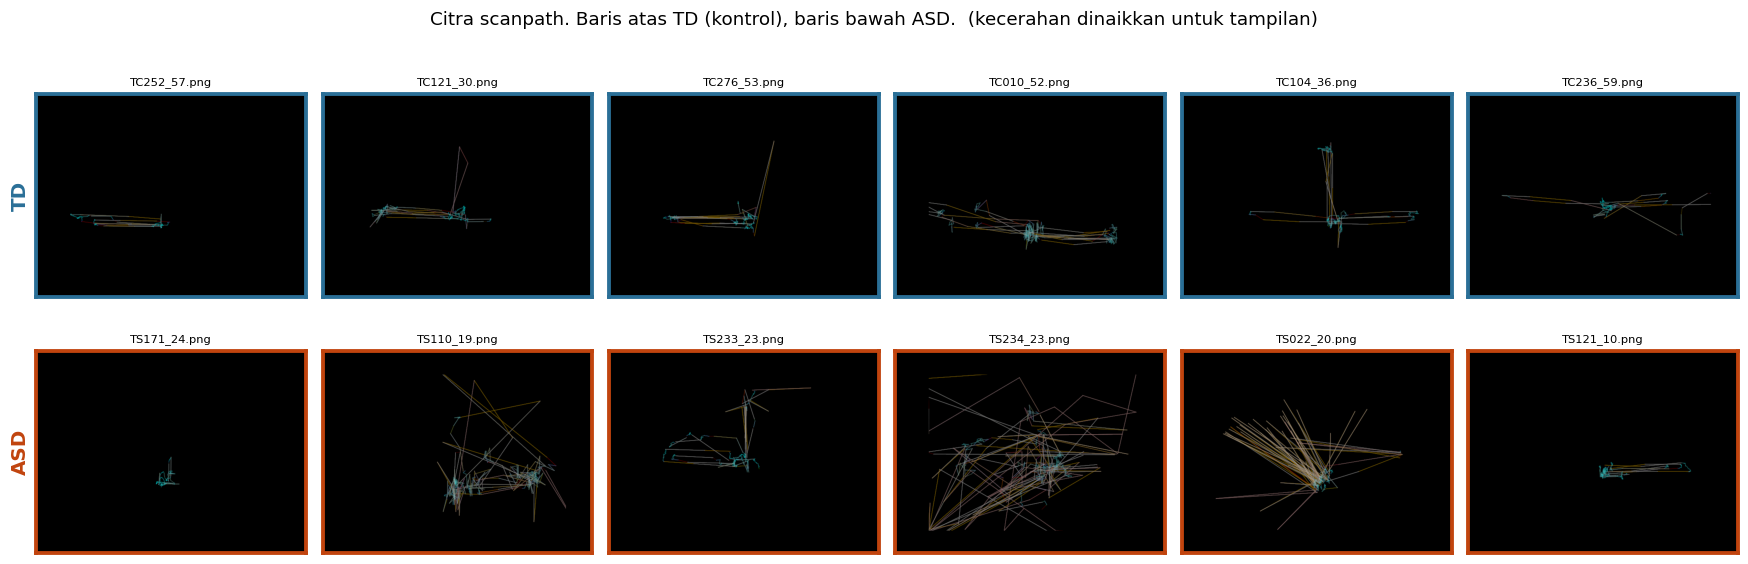

In [8]:
def boost(a, gamma=0.42):
    '''Naikkan kecerahan HANYA untuk tampilan. Tidak dipakai saat ekstraksi fitur.'''
    return np.clip(a ** gamma, 0, 1)

fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for row, grp in enumerate(["TD", "ASD"]):
    sel = meta[meta.group == grp].sample(6, random_state=RANDOM_STATE)
    for ax, (_, r) in zip(axes[row], sel.iterrows()):
        a = np.asarray(Image.open(r.path).convert("RGB")).astype(float)/255
        ax.imshow(boost(a)); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(r.file, fontsize=7.5)
        for s in ax.spines.values():
            s.set_color(PAL[grp]); s.set_linewidth(2.5); s.set_visible(True)
    axes[row][0].set_ylabel(grp, fontsize=13, fontweight="bold", color=PAL[grp])
fig.suptitle("Citra scanpath. Baris atas TD (kontrol), baris bawah ASD.  "
             "(kecerahan dinaikkan untuk tampilan)", fontsize=12)
plt.tight_layout(); plt.show()

Perhatikan pola yang sudah terlihat kasat mata: scanpath ASD cenderung **menyebar lebih luas**
ke seluruh bidang layar, sementara TD lebih **terkumpul** di area tertentu. Bagian 3 menguji
apakah kesan visual ini bertahan secara kuantitatif.

## 2. Ekstraksi fitur

Kami sengaja **tidak** memakai CNN di POC ini, dan itu keputusan desain, bukan keterbatasan:

1. **Interpretabilitas.** Alat skrining medis yang keluarannya angka tanpa penjelasan sulit diterima
   tenaga kesehatan. Fitur geometri bisa diterjemahkan jadi kalimat: *"pandangan anak ini 40% lebih
   tersebar dari rentang tipikal"*.
2. **Kelayakan di perangkat murah.** Fitur ini ringan, bisa dihitung di tablet Android kelas bawah
   tanpa GPU, syarat mutlak untuk deployment di Posyandu.
3. **Kejujuran statistik.** Dengan hanya 54 partisipan, CNN berparameter jutaan hampir pasti menghafal.

| Kelompok | Fitur | Interpretasi |
|---|---|---|
| **Cakupan** | `ink_frac` | Seberapa luas layar disapu pandangan |
| **Dispersi** | `std_x`, `std_y`, `span_x`, `span_y`, `radial_mean`, `radial_std` | Menyebar vs terfokus |
| **Posisi** | `centroid_x`, `centroid_y` | Ke mana pusat perhatian tertuju |
| **Dinamika** | `vel_mean/std`, `acc_mean`, `jerk_mean` | Kecepatan & kehalusan gerakan mata |
| **Perilaku** | `fixation_ratio`, `saccade_ratio` | Proporsi mengamati vs melompat |
| **Sebaran** | `grid_entropy`, `n_active_cells` | Merata ke seluruh layar atau menumpuk |
| **Struktur** | `bbox_fill`, `aspect_ratio` | Bentuk keseluruhan lintasan |

In [9]:
GRID = 8
INK_THRESHOLD = 0.02

def features_from_rgb(a):
    '''Inti ekstraksi fitur. Menerima array RGB ternormalisasi [0,1].'''
    H, W = a.shape[:2]
    R, G, B = a[:, :, 0], a[:, :, 1], a[:, :, 2]
    ink = a.sum(axis=2) > INK_THRESHOLD

    f = {}
    n_ink = int(ink.sum())
    f["ink_frac"] = n_ink / (H * W)

    if n_ink < 5:
        for k in ["centroid_x","centroid_y","std_x","std_y","span_x","span_y",
                  "radial_mean","radial_std","vel_mean","vel_std","acc_mean","jerk_mean",
                  "fixation_ratio","saccade_ratio","grid_entropy","n_active_cells",
                  "bbox_fill","aspect_ratio"]:
            f[k] = 0.0
        return f

    ys, xs = np.nonzero(ink)
    xn, yn = xs / W, ys / H

    f["centroid_x"], f["centroid_y"] = xn.mean(), yn.mean()
    f["std_x"], f["std_y"] = xn.std(), yn.std()
    f["span_x"] = xn.max() - xn.min()
    f["span_y"] = yn.max() - yn.min()
    rad = np.hypot(xn - xn.mean(), yn - yn.mean())
    f["radial_mean"], f["radial_std"] = rad.mean(), rad.std()

    r_i, g_i, b_i = R[ink], G[ink], B[ink]
    f["vel_mean"], f["vel_std"] = r_i.mean(), r_i.std()
    f["acc_mean"], f["jerk_mean"] = g_i.mean(), b_i.mean()

    denom = max(n_ink, 1)
    f["fixation_ratio"] = ((r_i < g_i*0.6) & (r_i < b_i*0.6)).sum() / denom
    f["saccade_ratio"]  = ((r_i > g_i*0.9) & (r_i > 0.05)).sum() / denom

    cell = np.zeros((GRID, GRID))
    gi = np.clip((yn*GRID).astype(int), 0, GRID-1)
    gj = np.clip((xn*GRID).astype(int), 0, GRID-1)
    np.add.at(cell, (gi, gj), 1)
    p = cell.ravel()/cell.sum(); p = p[p > 0]
    f["grid_entropy"] = float(-(p*np.log(p)).sum()/np.log(GRID*GRID))
    f["n_active_cells"] = float((cell > 0).sum()/(GRID*GRID))

    f["bbox_fill"] = f["ink_frac"]/max(f["span_x"]*f["span_y"], 1e-9)
    f["aspect_ratio"] = f["span_x"]/max(f["span_y"], 1e-9)
    return f

def extract_features(path):
    return features_from_rgb(np.asarray(Image.open(path).convert("RGB")).astype(np.float64)/255.0)

_demo = extract_features(meta.path.iloc[0])
print(f"Jumlah fitur per citra: {len(_demo)}\n")
for k, v in list(_demo.items())[:6]:
    print(f"  {k:16s} {v: .4f}")

Jumlah fitur per citra: 19

  ink_frac          0.0129
  centroid_x        0.4198
  centroid_y        0.5705
  std_x             0.1051
  std_y             0.1398
  span_x            0.3859


In [10]:
%%time
# Satu kali baca per citra: hitung fitur DAN akumulasi peta kepadatan sekaligus.
DM = (120, 160)
dm_acc = {0: np.zeros(DM), 1: np.zeros(DM)}
dm_cnt = {0: 0, 1: 0}

rows = []
for p, lab in zip(meta.path, meta.label):
    rows.append(extract_features(p))
    g = np.asarray(Image.open(p).convert("L").resize((DM[1], DM[0]))).astype(float)/255
    dm_acc[lab] += (g > 0.01).astype(float); dm_cnt[lab] += 1

dm_td, dm_asd = dm_acc[0]/dm_cnt[0], dm_acc[1]/dm_cnt[1]

X_df = pd.DataFrame(rows)
FEATURES = list(X_df.columns)
X, y, groups = X_df.values, meta.label.values, meta.participant.values

print(f"Matriks fitur : {X.shape[0]} citra x {X.shape[1]} fitur")
assert not np.isnan(X).any(), "Ada NaN pada matriks fitur"
print("Tidak ada NaN.")

Matriks fitur : 547 citra x 19 fitur
Tidak ada NaN.
CPU times: user 6.46 s, sys: 742 ms, total: 7.2 s
Wall time: 7.43 s


## 3. Exploratory Data Analysis

Bagian ini menjawab: *apa yang sebenarnya berbeda antara kedua kelompok, dan apakah perbedaannya
cukup konsisten untuk dijadikan dasar produk?*

### EDA 3, Kualitas data

Sebelum menarik kesimpulan apa pun, cek dulu apakah ada citra rusak, hampir kosong, atau outlier ekstrem.

Citra hampir kosong (ink_frac < 0.1%): 0

Citra dengan >=1 fitur di luar 4 SD: 20 dari 547


,file,group,ink_frac,n_fitur_ekstrem
14,TC020_54.png,TD,0.012764,1
34,TC040_39.png,TD,0.011084,2
43,TC049_37.png,TD,0.013997,1
55,TC061_50.png,TD,0.008447,1
87,TC098_54.png,TD,0.006676,1
88,TC099_54.png,TD,0.011104,1
100,TC111_37.png,TD,0.007673,1
218,TC234_59.png,TD,0.010420,1
222,TC243_57.png,TD,0.001449,7
233,TC254_59.png,TD,0.008216,1


/var/folders/cg/mk19_4755fxfc3thmsh50vhm0000gn/T/ipykernel_27489/3489231361.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=["TD","ASD"], patch_artist=True, widths=0.55)


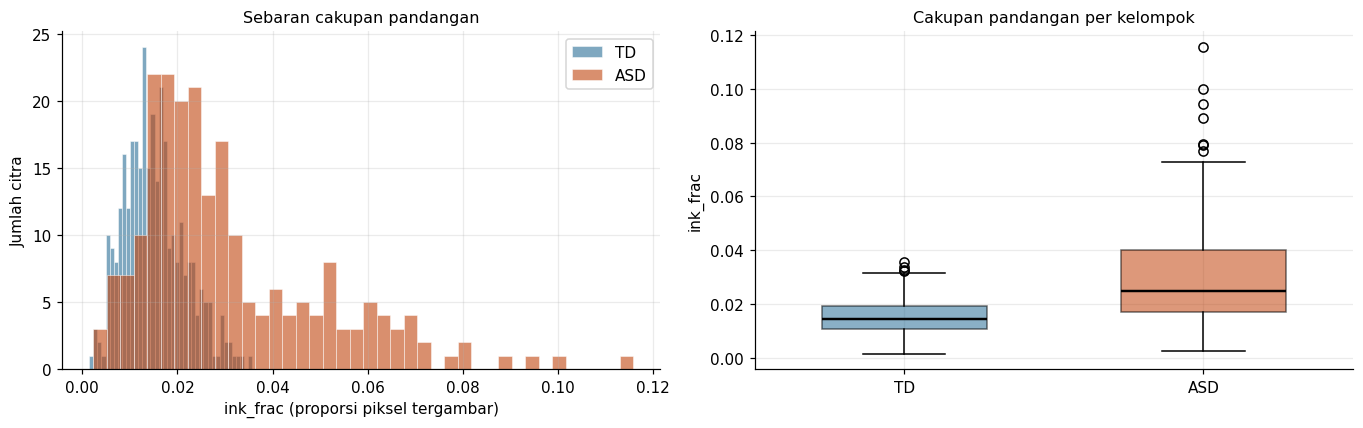

In [11]:
qc = X_df.copy(); qc["group"] = meta.group.values; qc["file"] = meta.file.values

near_empty = qc[qc.ink_frac < 0.001]
print(f"Citra hampir kosong (ink_frac < 0.1%): {len(near_empty)}")
if len(near_empty): display(near_empty[["file","group","ink_frac"]])

z = (X_df - X_df.mean())/X_df.std(ddof=0)
n_out = (z.abs() > 4).sum(axis=1)
print(f"\nCitra dengan >=1 fitur di luar 4 SD: {(n_out>0).sum()} dari {len(qc)}")
if (n_out > 0).any():
    display(qc.loc[n_out[n_out>0].index, ["file","group","ink_frac"]]
            .assign(n_fitur_ekstrem=n_out[n_out>0]).head(10))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4))
ax = axes[0]
for g in ["TD","ASD"]:
    ax.hist(qc[qc.group==g].ink_frac, bins=40, alpha=0.6, label=g, color=PAL[g],
            edgecolor="white", linewidth=0.5)
ax.set_xlabel("ink_frac (proporsi piksel tergambar)"); ax.set_ylabel("Jumlah citra")
ax.set_title("Sebaran cakupan pandangan", fontsize=10.5); ax.legend()

ax = axes[1]
data = [qc[qc.group==g].ink_frac.values for g in ["TD","ASD"]]
bp = ax.boxplot(data, labels=["TD","ASD"], patch_artist=True, widths=0.55)
for patch, g in zip(bp["boxes"], ["TD","ASD"]):
    patch.set_facecolor(PAL[g]); patch.set_alpha(0.55)
for med in bp["medians"]: med.set_color("black"); med.set_linewidth(1.6)
ax.set_ylabel("ink_frac"); ax.set_title("Cakupan pandangan per kelompok", fontsize=10.5)
plt.tight_layout(); plt.show()

### EDA 4, Profil spasial: ke mana anak memandang

Kami tumpuk seluruh citra tiap kelompok menjadi peta kepadatan rata-rata, lalu lihat selisihnya.

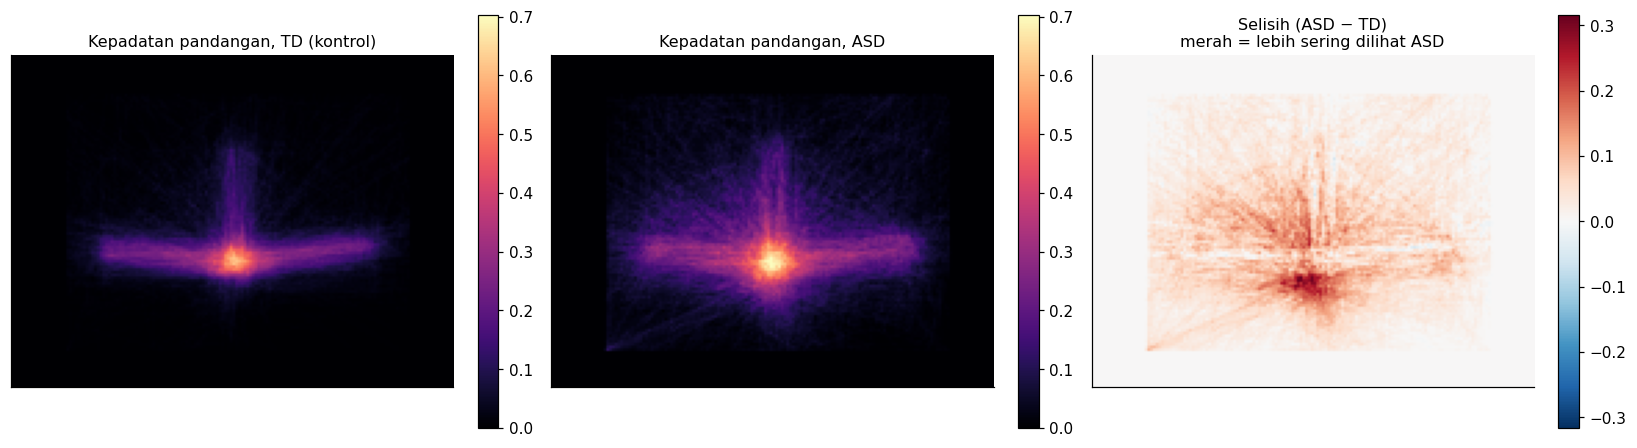

Konsentrasi pandangan di 30% area tengah layar (relatif thd rata-rata sendiri):
  TD  : 5.15x
  ASD : 4.07x

Angka >1 berarti pandangan terkonsentrasi di tengah. Semakin tinggi = semakin fokus.


In [12]:
diff = dm_asd - dm_td
fig, axes = plt.subplots(1, 3, figsize=(15, 4.1))
vmax = max(dm_td.max(), dm_asd.max())
for ax, (dmp, t) in zip(axes[:2], [(dm_td, "TD (kontrol)"), (dm_asd, "ASD")]):
    im = ax.imshow(dmp, cmap="magma", vmin=0, vmax=vmax)
    ax.set_title(f"Kepadatan pandangan, {t}", fontsize=10.5)
    plt.colorbar(im, ax=ax, fraction=0.045)
lim = np.abs(diff).max()
im = axes[2].imshow(diff, cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[2].set_title("Selisih (ASD − TD)\nmerah = lebih sering dilihat ASD", fontsize=10.5)
plt.colorbar(im, ax=axes[2], fraction=0.045)
for ax in axes: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

h, w = dm_td.shape
cy, cx = slice(int(h*0.35), int(h*0.65)), slice(int(w*0.35), int(w*0.65))
print("Konsentrasi pandangan di 30% area tengah layar (relatif thd rata-rata sendiri):")
print(f"  TD  : {dm_td[cy,cx].mean()/dm_td.mean():.2f}x")
print(f"  ASD : {dm_asd[cy,cx].mean()/dm_asd.mean():.2f}x")
print("\nAngka >1 berarti pandangan terkonsentrasi di tengah. Semakin tinggi = semakin fokus.")

#### Profil marginal: sebaran horizontal dan vertikal

Peta 2D di atas diproyeksikan ke sumbu x dan y supaya perbedaan sebarannya lebih mudah dibaca.

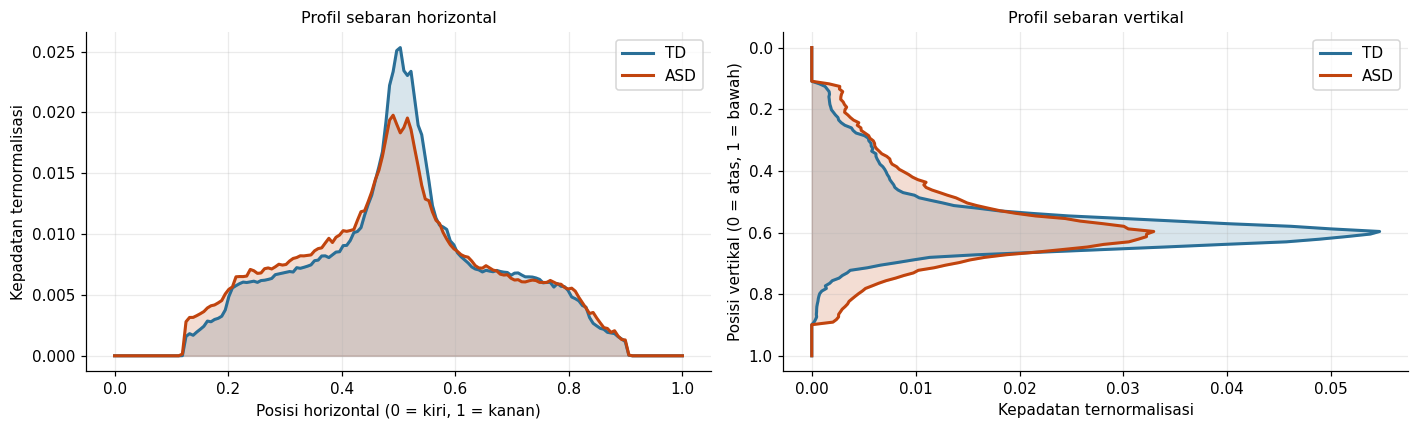

Catatan kehati-hatian:
Carette dkk. mencatat partisipan ASD cenderung melihat ke BAGIAN BAWAH layar, tempat
perangkat eye-tracker diletakkan. Kalau profil vertikal menunjukkan perbedaan di bawah,
itu bisa jadi artefak penempatan alat, bukan perilaku ASD murni. Ini ditulis sebagai
limitasi di paper, bukan dirayakan sebagai temuan.


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
xs_ax = np.linspace(0, 1, dm_td.shape[1]); ys_ax = np.linspace(0, 1, dm_td.shape[0])

ax = axes[0]
for dmp, g in [(dm_td, "TD"), (dm_asd, "ASD")]:
    prof = dmp.sum(axis=0); prof = prof/prof.sum()
    ax.plot(xs_ax, prof, lw=2, color=PAL[g], label=g)
    ax.fill_between(xs_ax, prof, alpha=0.18, color=PAL[g])
ax.set_xlabel("Posisi horizontal (0 = kiri, 1 = kanan)"); ax.set_ylabel("Kepadatan ternormalisasi")
ax.set_title("Profil sebaran horizontal", fontsize=10.5); ax.legend()

ax = axes[1]
for dmp, g in [(dm_td, "TD"), (dm_asd, "ASD")]:
    prof = dmp.sum(axis=1); prof = prof/prof.sum()
    ax.plot(prof, ys_ax, lw=2, color=PAL[g], label=g)
    ax.fill_betweenx(ys_ax, prof, alpha=0.18, color=PAL[g])
ax.invert_yaxis()
ax.set_ylabel("Posisi vertikal (0 = atas, 1 = bawah)"); ax.set_xlabel("Kepadatan ternormalisasi")
ax.set_title("Profil sebaran vertikal", fontsize=10.5); ax.legend()
plt.tight_layout(); plt.show()

print("Catatan kehati-hatian:")
print("Carette dkk. mencatat partisipan ASD cenderung melihat ke BAGIAN BAWAH layar, tempat")
print("perangkat eye-tracker diletakkan. Kalau profil vertikal menunjukkan perbedaan di bawah,")
print("itu bisa jadi artefak penempatan alat, bukan perilaku ASD murni. Ini ditulis sebagai")
print("limitasi di paper, bukan dirayakan sebagai temuan.")

#### Okupansi kuadran

Layar dibagi 3×3 untuk melihat area mana yang proporsinya berbeda antar kelompok.

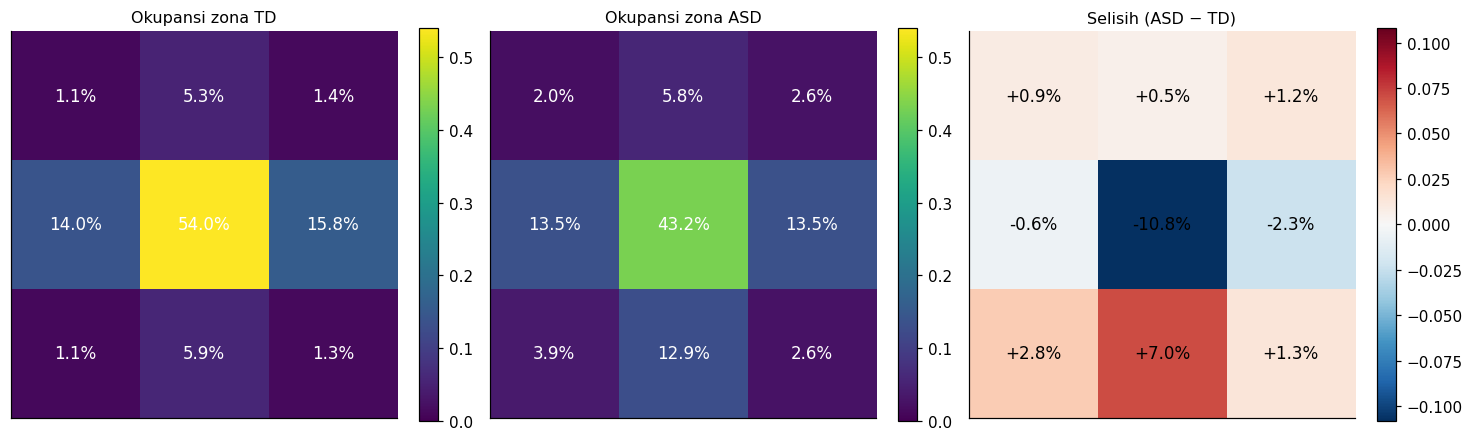

Zona tengah : TD 54.0%  vs  ASD 43.2%
Total tepi  : TD 46.0%  vs  ASD 56.8%


In [14]:
def zone_occupancy(dmp, n=3):
    H, W = dmp.shape
    out = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            out[i, j] = dmp[i*H//n:(i+1)*H//n, j*W//n:(j+1)*W//n].sum()
    return out/out.sum()

zt, za = zone_occupancy(dm_td), zone_occupancy(dm_asd)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4))
for ax, (z_, t) in zip(axes[:2], [(zt, "TD"), (za, "ASD")]):
    im = ax.imshow(z_, cmap="viridis", vmin=0, vmax=max(zt.max(), za.max()))
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{z_[i,j]:.1%}", ha="center", va="center", color="white", fontsize=11)
    ax.set_title(f"Okupansi zona {t}", fontsize=10.5)
    plt.colorbar(im, ax=ax, fraction=0.046)
dz = za - zt; lim = np.abs(dz).max()
im = axes[2].imshow(dz, cmap="RdBu_r", vmin=-lim, vmax=lim)
for i in range(3):
    for j in range(3):
        axes[2].text(j, i, f"{dz[i,j]:+.1%}", ha="center", va="center", fontsize=11)
axes[2].set_title("Selisih (ASD − TD)", fontsize=10.5)
plt.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes: ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

print(f"Zona tengah : TD {zt[1,1]:.1%}  vs  ASD {za[1,1]:.1%}")
print(f"Total tepi  : TD {1-zt[1,1]:.1%}  vs  ASD {1-za[1,1]:.1%}")

### EDA 5, Profil dinamika gerakan mata

Karena kanal warna membawa arti fisik (R = velocity, G = akselerasi, B = jerk),
sebaran intensitas tiap kanal langsung menggambarkan bagaimana mata anak bergerak.

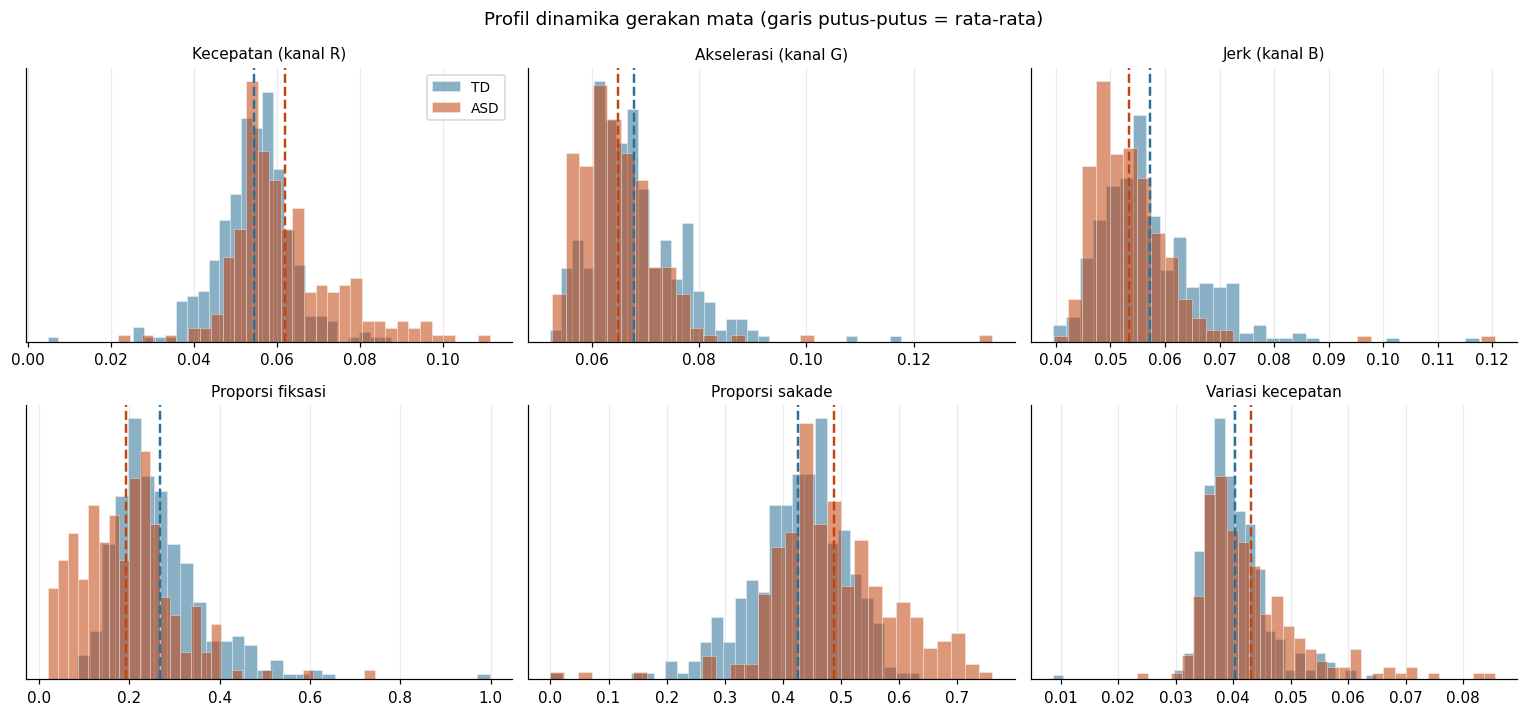

In [15]:
dyn = [("vel_mean","Kecepatan (kanal R)"), ("acc_mean","Akselerasi (kanal G)"),
       ("jerk_mean","Jerk (kanal B)"), ("fixation_ratio","Proporsi fiksasi"),
       ("saccade_ratio","Proporsi sakade"), ("vel_std","Variasi kecepatan")]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.6))
for ax, (feat, title) in zip(axes.ravel(), dyn):
    for g in ["TD","ASD"]:
        d = qc[qc.group==g][feat]
        ax.hist(d, bins=32, alpha=0.55, label=g, color=PAL[g], density=True,
                edgecolor="white", linewidth=0.4)
        ax.axvline(d.mean(), color=PAL[g], ls="--", lw=1.6)
    ax.set_title(title, fontsize=10); ax.set_yticks([])
axes[0][0].legend(fontsize=9)
fig.suptitle("Profil dinamika gerakan mata (garis putus-putus = rata-rata)", fontsize=12)
plt.tight_layout(); plt.show()

### EDA 6, Fitur mana yang paling memisahkan kedua kelompok

Kami pakai **Cohen's d** (ukuran efek terstandar), dihitung di level **rata-rata per partisipan**
supaya anak yang menyumbang banyak citra tidak mendominasi.

Patokan lazim: |d| ≈ 0,2 kecil · 0,5 sedang · **0,8 besar**.

In [16]:
pf = X_df.copy(); pf["participant"] = groups; pf["label"] = y
p_level = pf.groupby("participant").mean(numeric_only=True)

def cohens_d(a, b):
    na, nb = len(a), len(b)
    sp = np.sqrt(((na-1)*a.var(ddof=1) + (nb-1)*b.var(ddof=1))/(na+nb-2))
    return (a.mean()-b.mean())/sp if sp > 0 else 0.0

asd_p, td_p = p_level[p_level.label == 1], p_level[p_level.label == 0]
eff = pd.DataFrame({
    "TD_mean":  [td_p[f].mean() for f in FEATURES],
    "ASD_mean": [asd_p[f].mean() for f in FEATURES],
    "cohens_d": [cohens_d(asd_p[f], td_p[f]) for f in FEATURES],
}, index=FEATURES)
eff["abs_d"] = eff.cohens_d.abs()
eff = eff.sort_values("abs_d", ascending=False)
print(f"Level partisipan: {len(asd_p)} ASD vs {len(td_p)} TD\n")
display(eff.drop(columns="abs_d").head(12).round(4))

Level partisipan: 26 ASD vs 28 TD



,TD_mean,ASD_mean,cohens_d
n_active_cells,0.2082,0.3404,1.6852
ink_frac,0.0156,0.0330,1.4999
span_y,0.3973,0.5747,1.4779
grid_entropy,0.5074,0.6113,1.4708
radial_mean,0.1358,0.1681,1.3742
span_x,0.4831,0.6062,1.3119
radial_std,0.0719,0.0876,1.2945
vel_mean,0.0540,0.0628,1.2181
std_y,0.0877,0.1226,1.2126
fixation_ratio,0.2687,0.1834,-1.1498


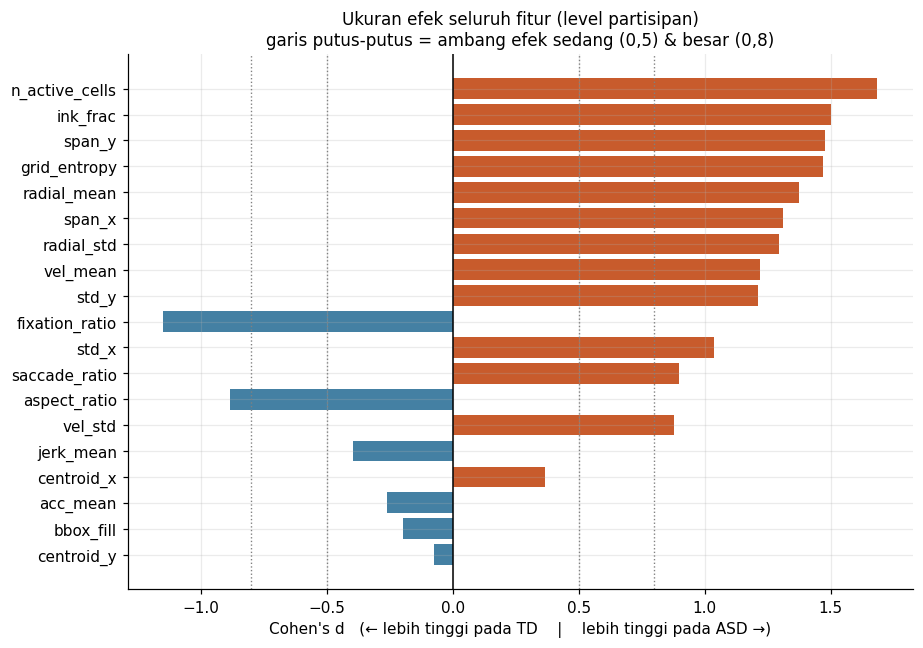

In [17]:
top = eff.iloc[::-1]
fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(top.index, top.cohens_d, color=[C_ASD if d > 0 else C_TD for d in top.cohens_d], alpha=0.88)
for x in [-0.8,-0.5,0.5,0.8]: ax.axvline(x, color="grey", ls=":", lw=0.9)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Cohen's d   (← lebih tinggi pada TD    |    lebih tinggi pada ASD →)")
ax.set_title("Ukuran efek seluruh fitur (level partisipan)\n"
             "garis putus-putus = ambang efek sedang (0,5) & besar (0,8)", fontsize=11)
plt.tight_layout(); plt.show()

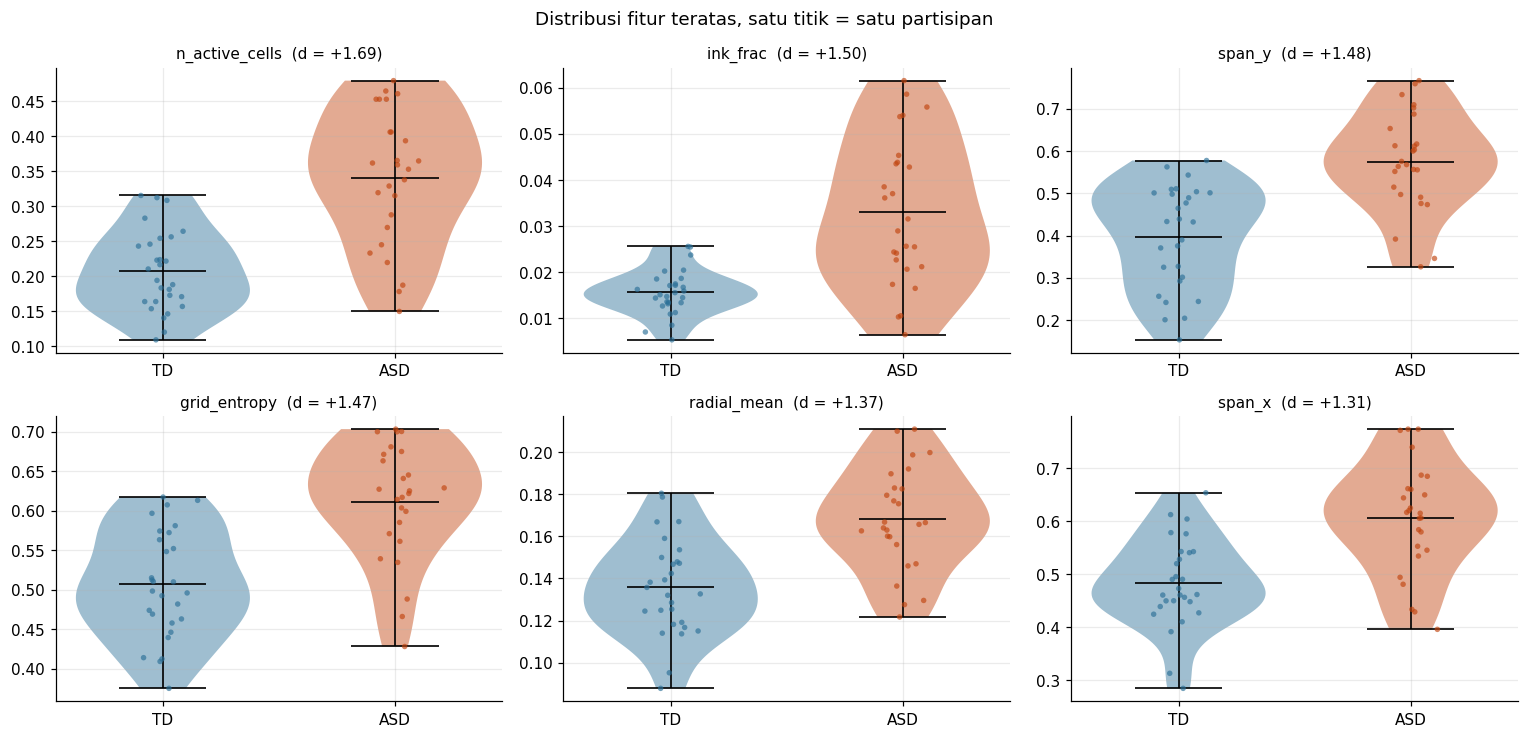

In [18]:
show = eff.head(6).index.tolist()
fig, axes = plt.subplots(2, 3, figsize=(14, 6.8))
for ax, feat in zip(axes.ravel(), show):
    d_td, d_asd = td_p[feat], asd_p[feat]
    parts = ax.violinplot([d_td, d_asd], positions=[0,1], showmeans=True, widths=0.75)
    for i, pc in enumerate(parts["bodies"]):
        pc.set_facecolor(C_TD if i == 0 else C_ASD); pc.set_alpha(0.45)
    for key in ["cmeans","cbars","cmins","cmaxes"]:
        parts[key].set_color("black"); parts[key].set_linewidth(1.1)
    for i, d in enumerate([d_td, d_asd]):
        ax.scatter(np.random.normal(i, 0.055, len(d)), d, s=13, alpha=0.65,
                   color=C_TD if i == 0 else C_ASD, edgecolor="none", zorder=3)
    ax.set_xticks([0,1]); ax.set_xticklabels(["TD","ASD"])
    ax.set_title(f"{feat}  (d = {eff.loc[feat,'cohens_d']:+.2f})", fontsize=10)
fig.suptitle("Distribusi fitur teratas, satu titik = satu partisipan", fontsize=12)
plt.tight_layout(); plt.show()

#### Hubungan antar dua fitur teratas

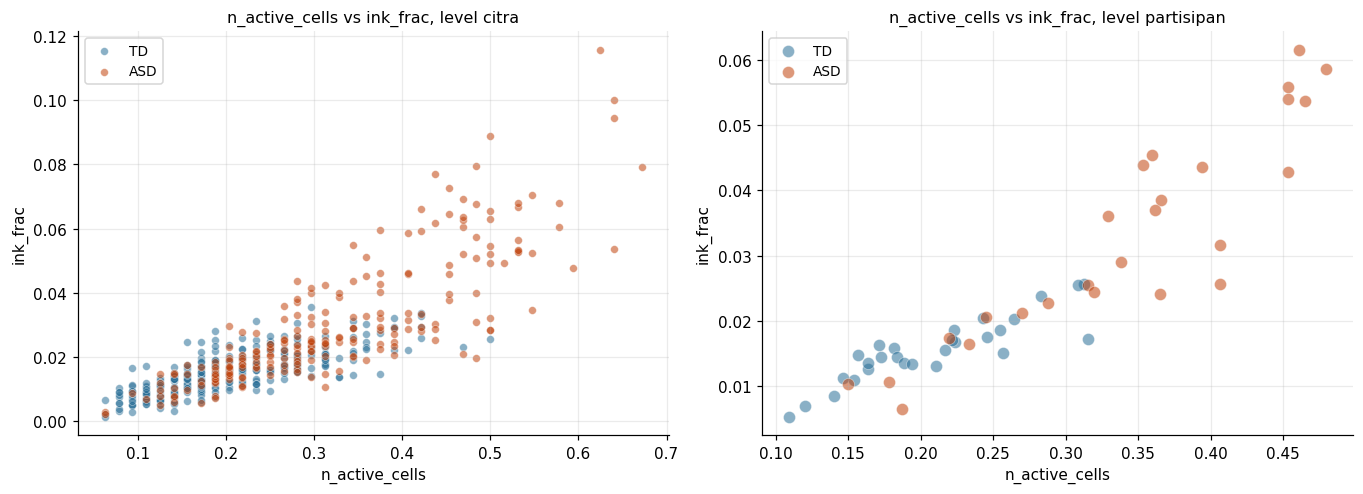

In [19]:
f1, f2 = eff.index[0], eff.index[1]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
for ax, (dd, lvl) in zip(axes, [(qc, "level citra"), (p_level.assign(
        group=np.where(p_level.label==1,"ASD","TD")), "level partisipan")]):
    for g in ["TD","ASD"]:
        s = dd[dd.group == g]
        ax.scatter(s[f1], s[f2], s=26 if lvl=="level citra" else 62, alpha=0.55,
                   color=PAL[g], label=g, edgecolor="white", linewidth=0.4)
    ax.set_xlabel(f1); ax.set_ylabel(f2); ax.set_title(f"{f1} vs {f2}, {lvl}", fontsize=10.5)
    ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

### EDA 7, Korelasi antar fitur

Fitur yang saling berkorelasi tinggi membawa informasi yang tumpang tindih. Ini penting untuk
menilai apakah 19 fitur benar-benar memberi 19 sudut pandang berbeda, atau sebenarnya
mengukur hal yang mirip.

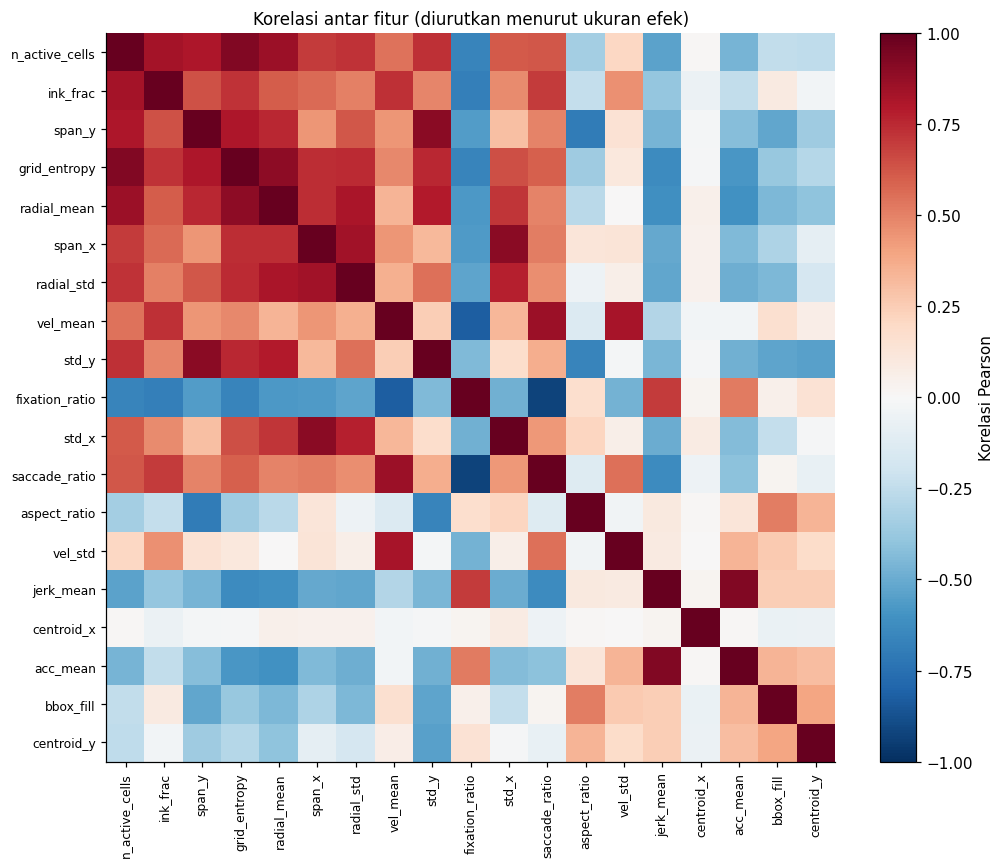

Pasangan fitur paling berkorelasi (|r| > 0.85):


,,r
n_active_cells,grid_entropy,0.926
jerk_mean,acc_mean,0.925
fixation_ratio,saccade_ratio,-0.923
span_x,std_x,0.903
span_y,std_y,0.900
grid_entropy,radial_mean,0.895
n_active_cells,radial_mean,0.857
vel_mean,saccade_ratio,0.856


In [20]:
corr = X_df.corr()
order = eff.index.tolist()
corr = corr.loc[order, order]

fig, ax = plt.subplots(figsize=(9.5, 8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=90, fontsize=8)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8)
ax.grid(False); plt.colorbar(im, ax=ax, fraction=0.046, label="Korelasi Pearson")
ax.set_title("Korelasi antar fitur (diurutkan menurut ukuran efek)", fontsize=11)
plt.tight_layout(); plt.show()

cu = corr.where(~np.tril(np.ones(corr.shape)).astype(bool)).stack()
print("Pasangan fitur paling berkorelasi (|r| > 0.85):")
hi = cu[cu.abs() > 0.85].sort_values(key=abs, ascending=False)
display(hi.round(3).to_frame("r") if len(hi) else "Tidak ada pasangan dengan |r| > 0.85")

### EDA 8, Struktur data dalam 2 dimensi (PCA)

Dua panel di bawah ini adalah **inti argumen metodologis** notebook ini.

- **Kiri.** Diwarnai menurut kelas. Menunjukkan seberapa terpisah ASD dan TD.
- **Kanan.** Diwarnai menurut **partisipan**. Kalau titik-titik dari anak yang sama menggerombol rapat,
  berarti setiap anak punya "sidik jari" scanpath sendiri. Dan kalau itu benar, split acak per citra
  akan membuat model tinggal mengenali anaknya, bukan kondisinya.

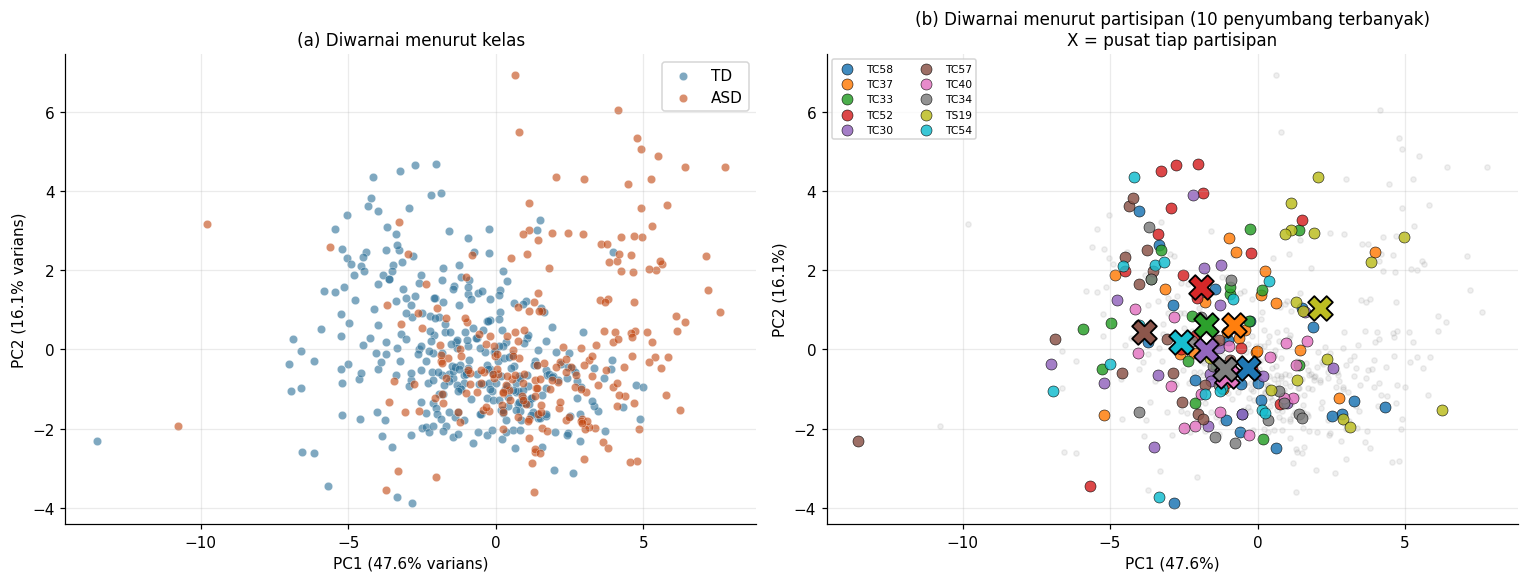

Dua komponen pertama menjelaskan 63.7% total varians.


In [21]:
Xs = StandardScaler().fit_transform(X)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(Xs)
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))

ax = axes[0]
for g in ["TD","ASD"]:
    m = meta.group.values == g
    ax.scatter(Z[m,0], Z[m,1], s=30, alpha=0.6, color=PAL[g], label=g,
               edgecolor="white", linewidth=0.3)
ax.set_xlabel(f"PC1 ({ev[0]:.1%} varians)"); ax.set_ylabel(f"PC2 ({ev[1]:.1%} varians)")
ax.set_title("(a) Diwarnai menurut kelas", fontsize=11); ax.legend()

ax = axes[1]
sel = pd.Series(groups).value_counts().head(10).index.tolist()
cmap = plt.cm.tab10
for i, pid in enumerate(sel):
    m = groups == pid
    ax.scatter(Z[m,0], Z[m,1], s=52, alpha=0.85, color=cmap(i % 10), label=pid,
               edgecolor="black", linewidth=0.4)
    ax.scatter(Z[m,0].mean(), Z[m,1].mean(), s=260, marker="X",
               color=cmap(i % 10), edgecolor="black", linewidth=1.2, zorder=5)
rest = ~np.isin(groups, sel)
ax.scatter(Z[rest,0], Z[rest,1], s=12, alpha=0.12, color="grey", zorder=0)
ax.set_xlabel(f"PC1 ({ev[0]:.1%})"); ax.set_ylabel(f"PC2 ({ev[1]:.1%})")
ax.set_title("(b) Diwarnai menurut partisipan (10 penyumbang terbanyak)\n"
             "X = pusat tiap partisipan", fontsize=11)
ax.legend(fontsize=7, ncol=2, loc="best")
plt.tight_layout(); plt.show()
print(f"Dua komponen pertama menjelaskan {ev.sum():.1%} total varians.")

#### Seberapa besar "sidik jari" tiap anak

Kesan visual di panel kanan perlu diangkakan. Kami hitung, untuk tiap fitur, berapa proporsi
varians yang dijelaskan oleh **identitas partisipan** (mirip intraclass correlation).

Nilai tinggi = citra dari anak yang sama sangat mirip satu sama lain = **risiko kebocoran besar**
kalau split dilakukan per citra.

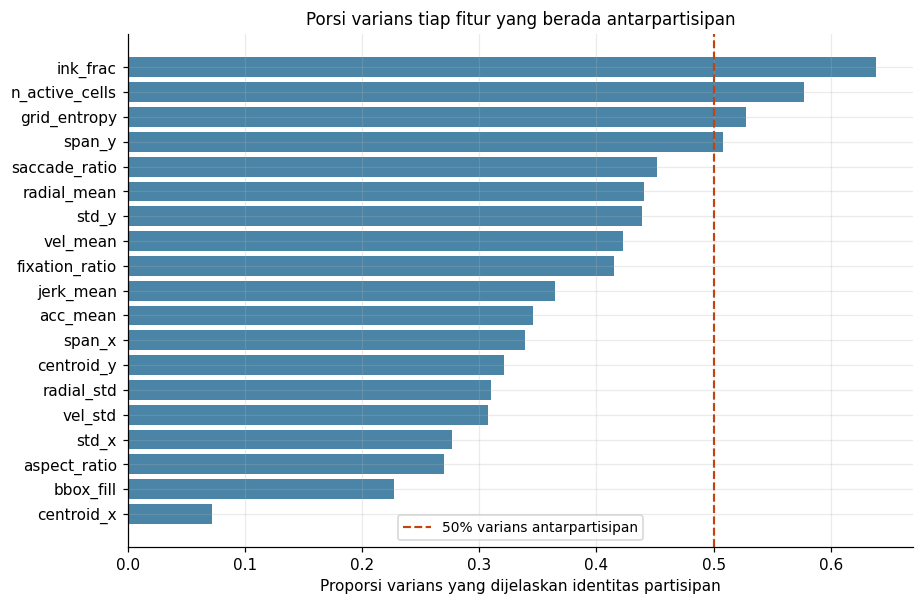

Rata-rata across fitur : 38.2%
Fitur paling khas-anak : ink_frac (63.8%)

Artinya rata-rata 38% variasi fitur berada pada tingkat ANTARPARTISIPAN.
Karena tiap anak hanya berada pada satu kelompok diagnosis, identitas bersarang di
dalam kondisi, sehingga angka ini TIDAK memisahkan variasi individual dari variasi
diagnosis. Yang ditunjukkannya cukup untuk keperluan kami: citra berulang dari anak
yang sama bukan pengamatan independen, sehingga evaluasi harus dikelompokkan per
partisipan. Pemisahan kausalnya menuntut model hierarkis fitur ~ diagnosis + (1|anak).
Dampak pengelompokan diuji di Bagian 4.


In [22]:
def variance_explained_by_group(v, g):
    df = pd.DataFrame({"v": v, "g": g})
    gm = df.groupby("g").v.transform("mean")
    ss_tot = ((df.v - df.v.mean())**2).sum()
    ss_between = ((gm - df.v.mean())**2).sum()
    return ss_between/ss_tot if ss_tot > 0 else 0.0

icc = pd.Series({f: variance_explained_by_group(X_df[f].values, groups) for f in FEATURES}
                ).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 5.6))
ax.barh(icc.index[::-1], icc.values[::-1], color=C_TD, alpha=0.85)
ax.axvline(0.5, color=C_ASD, ls="--", lw=1.4, label="50% varians antarpartisipan")
ax.set_xlabel("Proporsi varians yang dijelaskan identitas partisipan")
ax.set_title("Porsi varians tiap fitur yang berada antarpartisipan", fontsize=11)
ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

print(f"Rata-rata across fitur : {icc.mean():.1%}")
print(f"Fitur paling khas-anak : {icc.index[0]} ({icc.iloc[0]:.1%})")
print(f"\nArtinya rata-rata {icc.mean():.0%} variasi fitur berada pada tingkat ANTARPARTISIPAN.")
print("Karena tiap anak hanya berada pada satu kelompok diagnosis, identitas bersarang di")
print("dalam kondisi, sehingga angka ini TIDAK memisahkan variasi individual dari variasi")
print("diagnosis. Yang ditunjukkannya cukup untuk keperluan kami: citra berulang dari anak")
print("yang sama bukan pengamatan independen, sehingga evaluasi harus dikelompokkan per")
print("partisipan. Pemisahan kausalnya menuntut model hierarkis fitur ~ diagnosis + (1|anak).")
print("Dampak pengelompokan diuji di Bagian 4.")

### Ringkasan EDA

Pola yang muncul konsisten di berbagai sudut pandang: **scanpath anak ASD lebih tersebar dan menyapu
area lebih luas**, sementara anak TD pandangannya lebih terkonsentrasi.

Ini sejalan dengan literatur atensi sosial: anak TD cenderung mengunci pandangan pada wajah dan
elemen sosial dalam adegan, sedangkan anak ASD menyebar perhatian lebih merata ke seluruh layar
tanpa prioritas sosial yang sama kuatnya.

Nilainya untuk produk: keluaran model bisa disampaikan dalam bahasa manusia kepada kader dan orang tua,
bukan sekadar angka probabilitas tanpa konteks.

Tapi EDA juga memunculkan dua peringatan yang dibawa ke bagian berikutnya:

1. Sebagian besar varians antar-citra berada pada tingkat **antarpartisipan**, sehingga citra berulang dari anak yang sama bukan pengamatan independen → evaluasi wajib group-aware.
2. Perbedaan pada sumbu vertikal berpotensi **artefak penempatan alat**, bukan perilaku murni.

## 4. Demonstrasi kebocoran data

Dataset berisi **547 citra dari hanya 54 partisipan**. Kalau data dibagi secara acak per citra,
hampir pasti citra dari anak yang sama muncul di data latih dan data uji sekaligus. Model tidak perlu
belajar mengenali ASD, cukup menghafal ciri khas tiap anak, yang menurut EDA 8 memang kuat.

| Protokol | Cara split | Menjawab pertanyaan |
|---|---|---|
| `StratifiedKFold` | Acak per citra | *"Bisakah model mengenali citra dari anak yang sudah pernah dilihatnya?"* |
| `GroupKFold` | Acak per anak | *"Bisakah model mengenali anak yang belum pernah dilihat sama sekali?"* |

Hanya kolom kedua yang relevan untuk klaim kelayakan klinis.

In [23]:
MODELS = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    "SVM (RBF)":           make_pipeline(StandardScaler(), SVC(probability=True, random_state=RANDOM_STATE)),
    "Naive Bayes":         make_pipeline(StandardScaler(), GaussianNB()),
    "Random Forest":       RandomForestClassifier(n_estimators=400, min_samples_leaf=2,
                                                  random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
}

def auc_cv(model, X, y, cv, groups=None):
    pred = cross_val_predict(model, X, y, cv=cv, groups=groups, method="predict_proba")[:, 1]
    return roc_auc_score(y, pred), pred

rows, preds_grouped = [], {}
for name, mdl in MODELS.items():
    auc_leak, _ = auc_cv(mdl, X, y, StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE))
    auc_grp, pr = auc_cv(mdl, X, y, GroupKFold(n_splits=5), groups=groups)
    preds_grouped[name] = pr
    rows.append({"Model": name, "AUC per-citra (bocor)": auc_leak,
                 "AUC per-partisipan (jujur)": auc_grp, "Selisih": auc_leak-auc_grp})

leak = pd.DataFrame(rows).set_index("Model").sort_values("AUC per-partisipan (jujur)", ascending=False)
display(leak.round(4))
print(f"\nRata-rata penggelembungan akibat split per-citra: +{leak['Selisih'].mean():.4f} AUC")

,AUC per-citra (bocor),AUC per-partisipan (jujur),Selisih
Model,,,
Naive Bayes,0.7919,0.7753,0.0166
Gradient Boosting,0.7950,0.7655,0.0295
Random Forest,0.8037,0.7627,0.0410
Logistic Regression,0.8133,0.7531,0.0602
SVM (RBF),0.8054,0.7333,0.0721



Rata-rata penggelembungan akibat split per-citra: +0.0439 AUC


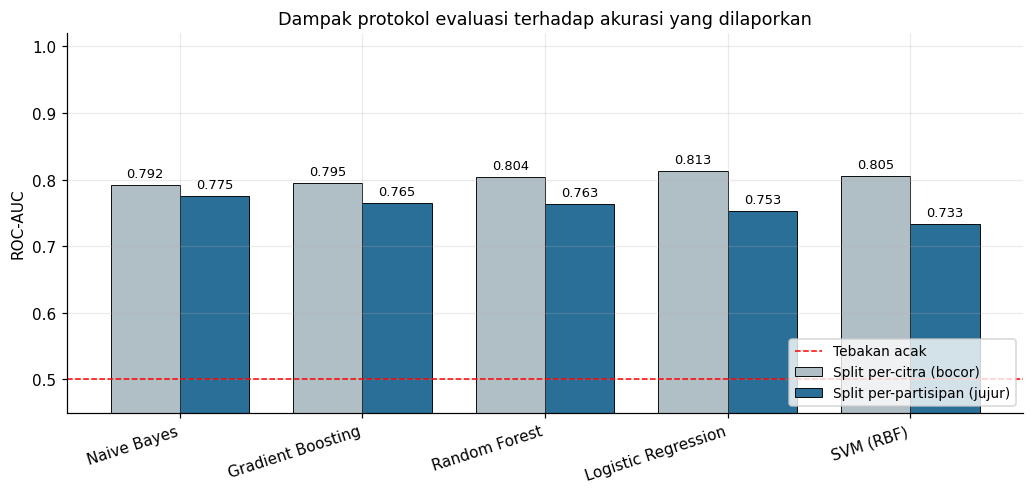

In [24]:
fig, ax = plt.subplots(figsize=(9.5, 4.6))
idx = np.arange(len(leak)); w = 0.38
ax.bar(idx-w/2, leak["AUC per-citra (bocor)"], w, label="Split per-citra (bocor)",
       color="#B0BEC5", edgecolor="black", linewidth=0.6)
ax.bar(idx+w/2, leak["AUC per-partisipan (jujur)"], w, label="Split per-partisipan (jujur)",
       color=C_TD, edgecolor="black", linewidth=0.6)
for i, (a, b) in enumerate(zip(leak["AUC per-citra (bocor)"], leak["AUC per-partisipan (jujur)"])):
    ax.text(i-w/2, a+0.012, f"{a:.3f}", ha="center", fontsize=8.5)
    ax.text(i+w/2, b+0.012, f"{b:.3f}", ha="center", fontsize=8.5)
ax.axhline(0.5, color="red", ls="--", lw=1, label="Tebakan acak")
ax.set_xticks(idx); ax.set_xticklabels(leak.index, rotation=18, ha="right")
ax.set_ylabel("ROC-AUC"); ax.set_ylim(0.45, 1.02)
ax.set_title("Dampak protokol evaluasi terhadap akurasi yang dilaporkan", fontsize=11.5)
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout(); plt.show()

### Hasilnya jujur: efeknya nyata tapi sedang

Penggelembungan dari split per-citra saja ternyata **moderat**, bukan dramatis. Kami laporkan apa adanya, sebab
melebih-lebihkan angka ini justru akan melemahkan argumen kami sendiri.

Penjelasannya masuk akal: fitur yang kami pakai bersifat **global dan kasar** (dispersi, cakupan, entropi),
sehingga tidak banyak menyediakan sidik jari halus untuk dihafal. Kebocoran akan jauh lebih parah pada
CNN yang bisa menghafal tekstur tiap citra.

Sumber kebocoran kedua, yaitu tersebarnya citra dari anak yang sama, ternyata jauh lebih besar.
Bagian berikut menguraikannya.

### Mengurai sumber penggelembungan

Carette dkk. membuat **2.735 citra sintetis** (5 turunan per citra asli) lalu menjalankan
cross-validation di atas gabungan data itu, tanpa mengelompokkan data per partisipan.
Ada dua mekanisme kebocoran yang bercampur di sana, dan keduanya perlu dipisahkan:

1. **Antarsalinan augmentasi.** Turunan rotasi/geser dari citra yang sama berada di data latih
   dan data uji sekaligus.
2. **Antaranak.** Citra berbeda dari anak yang sama tersebar antara data latih dan data uji.

Empat protokol di bawah memisahkan keduanya. B mengelompokkan salinan augmentasi menurut citra
sumbernya, sehingga selisih A - B mengisolasi mekanisme pertama; C menambahkan pengelompokan per
partisipan, sehingga selisih B - C mengisolasi mekanisme kedua. D melepas augmentasi sepenuhnya.

In [25]:
%%time
def augment_variants(path, n=5, seed=0):
    '''Augmentasi ala Keras ImageDataGenerator: rotasi, geser, zoom kecil.'''
    rng = np.random.default_rng(seed)
    im = Image.open(path).convert("RGB"); W, H = im.size
    out = []
    for _ in range(n):
        ang = float(rng.uniform(-15, 15))
        tx, ty = float(rng.uniform(-0.08, 0.08)*W), float(rng.uniform(-0.08, 0.08)*H)
        zoom = float(rng.uniform(0.9, 1.1))
        im2 = im.rotate(ang, resample=Image.BILINEAR, translate=(tx, ty))
        nw, nh = max(int(W*zoom), 8), max(int(H*zoom), 8)
        im2 = im2.resize((nw, nh), Image.BILINEAR)
        canvas = Image.new("RGB", (W, H), (0, 0, 0))
        canvas.paste(im2, ((W-nw)//2, (H-nh)//2))
        out.append(np.asarray(canvas).astype(np.float64)/255.0)
    return out

aug_rows, aug_y, aug_groups, aug_src = [], [], [], []
for i, (p, lab, gp) in enumerate(zip(meta.path, meta.label, groups)):
    aug_rows.append(extract_features(p)); aug_y.append(lab); aug_groups.append(gp); aug_src.append(i)
    for v in augment_variants(p, n=5, seed=i):
        aug_rows.append(features_from_rgb(v)); aug_y.append(lab)
        aug_groups.append(gp); aug_src.append(i)

X_aug = pd.DataFrame(aug_rows)[FEATURES].values
y_aug, g_aug, src_aug = np.array(aug_y), np.array(aug_groups), np.array(aug_src)
print(f"Dataset teraugmentasi: {X_aug.shape[0]} sampel "
      f"({len(meta)} asli + {X_aug.shape[0]-len(meta)} sintetis)")

Dataset teraugmentasi: 3282 sampel (547 asli + 2735 sintetis)
CPU times: user 44.4 s, sys: 5.39 s, total: 49.8 s
Wall time: 49.9 s


In [26]:
mdl = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))

auc_A = roc_auc_score(y_aug, cross_val_predict(mdl, X_aug, y_aug,
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), method="predict_proba")[:,1])
auc_B = roc_auc_score(y_aug, cross_val_predict(mdl, X_aug, y_aug,
        cv=GroupKFold(n_splits=5), groups=src_aug, method="predict_proba")[:,1])
auc_C = roc_auc_score(y_aug, cross_val_predict(mdl, X_aug, y_aug,
        cv=GroupKFold(n_splits=5), groups=g_aug, method="predict_proba")[:,1])
auc_D = roc_auc_score(y, preds_grouped["Logistic Regression"])

prot = pd.DataFrame({
    "Protokol": ["A. Augmentasi + split acak per sampel (ala literatur)",
                 "B. Augmentasi + group per citra sumber",
                 "C. Augmentasi + group per partisipan",
                 "D. Tanpa augmentasi + group per partisipan (kami pakai ini)"],
    "AUC": [auc_A, auc_B, auc_C, auc_D]}).set_index("Protokol")
prot["Selisih vs D"] = prot.AUC - auc_D
display(prot.round(4))

print(f"\nTotal penggelembungan A dibanding D            : {auc_A-auc_D:+.4f} AUC")
print(f"Kebocoran antarsalinan augmentasi     (A - B) : {auc_A-auc_B:+.4f} AUC")
print(f"Tidak mengelompokkan per partisipan   (B - C) : {auc_B-auc_C:+.4f} AUC")
print(f"Augmentasi saat split sudah benar     (C - D) : {auc_C-auc_D:+.4f} AUC")
print("\nA dan C sama-sama memakai augmentasi, sehingga selisih A - C mengukur")
print("mekanisme split dan bukan efek augmentasi. Dekomposisi yang benar memakai B")
print("sebagai perantara: B mengelompokkan salinan augmentasi per citra sumber,")
print("C mengelompokkan per partisipan.")

,AUC,Selisih vs D
Protokol,,
A. Augmentasi + split acak per sampel (ala literatur),0.8158,0.0626
B. Augmentasi + group per citra sumber,0.7968,0.0436
C. Augmentasi + group per partisipan,0.7484,-0.0048
D. Tanpa augmentasi + group per partisipan (kami pakai ini),0.7531,0.0000



Total penggelembungan A dibanding D            : +0.0626 AUC
Kebocoran antarsalinan augmentasi     (A - B) : +0.0190 AUC
Tidak mengelompokkan per partisipan   (B - C) : +0.0484 AUC
Augmentasi saat split sudah benar     (C - D) : -0.0048 AUC

A dan C sama-sama memakai augmentasi, sehingga selisih A - C mengukur
mekanisme split dan bukan efek augmentasi. Dekomposisi yang benar memakai B
sebagai perantara: B mengelompokkan salinan augmentasi per citra sumber,
C mengelompokkan per partisipan.


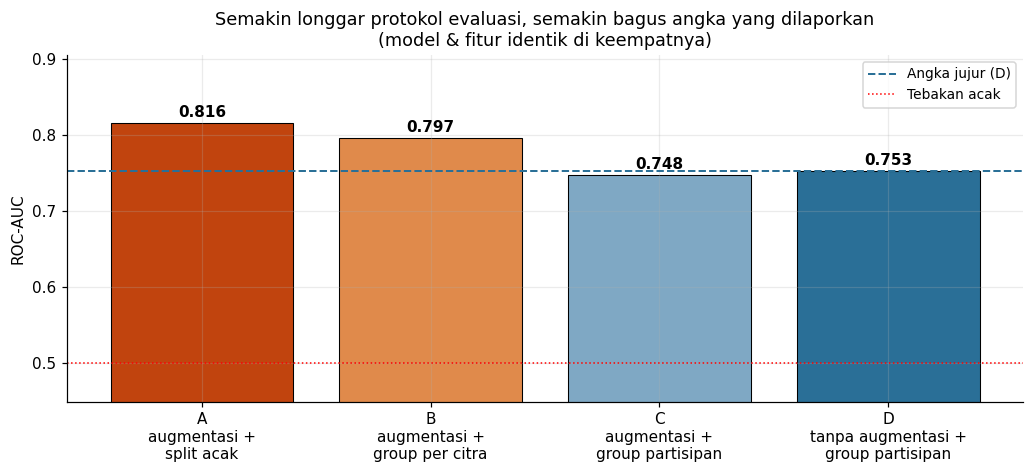

In [27]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
labels = ["A\naugmentasi +\nsplit acak", "B\naugmentasi +\ngroup per citra",
          "C\naugmentasi +\ngroup partisipan", "D\ntanpa augmentasi +\ngroup partisipan"]
bars = ax.bar(labels, prot.AUC.values, color=["#C1440E","#E08A4B","#7FA8C4",C_TD],
              edgecolor="black", linewidth=0.7)
for b, v in zip(bars, prot.AUC.values):
    ax.text(b.get_x()+b.get_width()/2, v+0.008, f"{v:.3f}", ha="center",
            fontsize=10, fontweight="bold")
ax.axhline(auc_D, color=C_TD, ls="--", lw=1.3, label="Angka jujur (D)")
ax.axhline(0.5, color="red", ls=":", lw=1, label="Tebakan acak")
ax.set_ylabel("ROC-AUC"); ax.set_ylim(0.45, min(1.02, prot.AUC.max()+0.09))
ax.set_title("Semakin longgar protokol evaluasi, semakin bagus angka yang dilaporkan\n"
             "(model & fitur identik di keempatnya)", fontsize=11.5)
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

### Perbandingan dengan literatur

Carette dkk. (2019) melaporkan **AUC > 0,9** pada dataset yang persis sama. Setelah membaca makalahnya,
selisih itu berasal dari dua mekanisme yang bercampur, dan porsinya tidak seimbang:
**tidak adanya pengelompokan per partisipan** menyumbang bagian terbesar, sedangkan **kebocoran
antarsalinan hasil augmentasi** menyumbang sisanya. Augmentasi itu sendiri, ketika pembagian data
sudah dikelompokkan per partisipan, tidak menaikkan AUC.

Yang menarik: **angka mereka sendiri mendukung temuan kami.** Di makalah yang sama, model non-neural
(Naive Bayes, Logistic Regression, SVM, Random Forest) hanya mencapai **AUC ≈ 0,7**. Baru model neural
di atas data teraugmentasi yang melonjak ke >0,9.

Hasil kami di bawah protokol group-aware konsisten dengan rentang non-neural tersebut, yang menguatkan
dugaan bahwa lompatan ke >0,9 itu **artefak metodologis, bukan kemampuan model yang sesungguhnya**.

Ini bukan kritik terhadap penulisnya. Ini penegasan bahwa untuk alat yang diklaim layak dipakai di layanan
kesehatan, protokol evaluasi harus mencerminkan kondisi penggunaan nyata: **anak yang belum pernah dilihat model.**

## 5. Hasil utama (protokol jujur)

Seluruh angka mulai bagian ini memakai **GroupKFold per partisipan**.

Dua hal ditetapkan lebih dahulu, sebelum hasil dilihat, supaya tidak terjadi pemilihan angka
yang paling menguntungkan:

1. **Unit keputusan produk adalah anak**, bukan rekaman. Endpoint utama karena itu AUC level anak.
2. **Model pra-tetap adalah regresi logistik**, model paling sederhana pada daftar. Model lain
   tetap dilaporkan sebagai pembanding, tetapi titik kerja dan angka utama memakai model pra-tetap.

Interval kepercayaan dihitung lewat **bootstrap di level partisipan**, karena partisipanlah unit
pengamatan yang sesungguhnya independen.

In [28]:
def bootstrap_auc_ci(y_true, y_score, groups, n_boot=2000, alpha=0.05, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    uniq = np.unique(groups)
    idx_by_g = {g: np.where(groups == g)[0] for g in uniq}
    stats = []
    for _ in range(n_boot):
        pick = rng.choice(uniq, size=len(uniq), replace=True)
        idx = np.concatenate([idx_by_g[g] for g in pick])
        if len(np.unique(y_true[idx])) < 2: continue
        stats.append(roc_auc_score(y_true[idx], y_score[idx]))
    lo, hi = np.percentile(stats, [100*alpha/2, 100*(1-alpha/2)])
    return lo, hi, np.array(stats)

# Model pra-tetap: ditetapkan sebelum hasil dilihat.
PRIMARY = "Logistic Regression"

res = []
for name, pr in preds_grouped.items():
    lo, hi, _ = bootstrap_auc_ci(y, pr, groups)
    res.append({"Model": name, "AUC": roc_auc_score(y, pr), "CI 95% bawah": lo,
                "CI 95% atas": hi, "Avg Precision": average_precision_score(y, pr)})
res_df = pd.DataFrame(res).set_index("Model").sort_values("AUC", ascending=False)
display(res_df.round(4))

BEST_RECORD = res_df.index[0]           # AUC tertinggi pada level rekaman
best_pred = preds_grouped[BEST_RECORD]  # dipakai hanya sebagai pembanding
primary_pred = preds_grouped[PRIMARY]
b_lo, b_hi, b_dist = bootstrap_auc_ci(y, primary_pred, groups)

print(f"\nModel pra-tetap        : {PRIMARY}")
print(f"  AUC level rekaman    = {roc_auc_score(y, primary_pred):.4f}  (95% CI {b_lo:.3f}-{b_hi:.3f})")
print(f"AUC rekaman tertinggi  : {BEST_RECORD} = {roc_auc_score(y, best_pred):.4f}")
print("\nPeringkat di atas dihitung pada level rekaman. Unit keputusan produk adalah anak,")
print(f"jadi endpoint utama ada pada sel berikutnya. CI lebar karena hanya ada {len(np.unique(groups))} partisipan.")

,AUC,CI 95% bawah,CI 95% atas,Avg Precision
Model,,,,
Naive Bayes,0.7753,0.6833,0.8583,0.7420
Gradient Boosting,0.7655,0.6788,0.8424,0.7352
Random Forest,0.7627,0.6749,0.8475,0.7367
Logistic Regression,0.7531,0.6578,0.8368,0.7218
SVM (RBF),0.7333,0.6419,0.8214,0.7139



Model pra-tetap        : Logistic Regression
  AUC level rekaman    = 0.7531  (95% CI 0.658-0.837)
AUC rekaman tertinggi  : Naive Bayes = 0.7753

Peringkat di atas dihitung pada level rekaman. Unit keputusan produk adalah anak,
jadi endpoint utama ada pada sel berikutnya. CI lebar karena hanya ada 54 partisipan.


### Metrik pada unit keputusan produk: anak, bukan rekaman

GroupKFold menjamin anak di data uji tidak pernah dilihat model, tetapi AUC di atas masih
dihitung atas 547 prediksi rekaman. Akibatnya anak yang menyumbang lebih banyak rekaman mendapat
bobot lebih besar, padahal produk hanya mengeluarkan satu keputusan per anak.

Sel berikut mengagregasi probabilitas out-of-fold menjadi satu nilai per anak, lalu melaporkan
`auc_record_level` dan `auc_child_level` secara terpisah. **Endpoint utama adalah level anak pada
model pra-tetap**, dan titik kerja dihitung di sana. Sel ini juga menjalankan **nested GroupKFold**
agar estimasi tidak memuat bias dari proses pemilihan model.

In [29]:
def to_participant_level(pred, y, groups):
    """Rata-ratakan probabilitas per anak; label anak konsisten dalam grup."""
    df = pd.DataFrame({"p": pred, "y": y, "g": groups})
    agg = df.groupby("g").agg(p=("p", "mean"), y=("y", "max"))
    return agg.p.values, agg.y.values.astype(int)


def bootstrap_ci(p, y, n_boot=2000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:
            continue
        stats.append(roc_auc_score(y[idx], p[idx]))
    return np.percentile(stats, [2.5, 97.5])


def titik_kerja(p, y_true, target_sens=0.90):
    """Ambang terendah yang menjaga sensitivitas >= target, dengan spesifisitas terbaik."""
    fpr_, tpr_, thr_ = roc_curve(y_true, p)
    ok = np.flatnonzero(tpr_ >= target_sens)
    j = ok[np.argmin(fpr_[ok])]
    return {"threshold": float(thr_[j]), "sensitivity": float(tpr_[j]),
            "specificity": float(1 - fpr_[j])}


auc_record_level, auc_child_level, prob_anak = {}, {}, {}
for name, pr in preds_grouped.items():
    p_anak, y_anak = to_participant_level(pr, y, groups)
    prob_anak[name] = p_anak
    auc_record_level[name] = roc_auc_score(y, pr)
    auc_child_level[name] = roc_auc_score(y_anak, p_anak)

dua = (pd.DataFrame({"AUC level rekaman": auc_record_level, "AUC level anak": auc_child_level})
       .rename_axis("Model").sort_values("AUC level anak", ascending=False))
display(dua.round(4))

p_prim = prob_anak[PRIMARY]
lo_a, hi_a = bootstrap_ci(p_prim, y_anak)
BEST_CHILD = max(auc_child_level, key=auc_child_level.get)

print(f"\nUnit keputusan produk adalah anak: {len(y_anak)} anak, {int(y_anak.sum())} ASD.")
print(f"  ENDPOINT UTAMA  {PRIMARY:20s} AUC anak = {auc_child_level[PRIMARY]:.4f} (95% CI {lo_a:.3f}-{hi_a:.3f})")
print(f"  pembanding      {BEST_RECORD:20s} AUC anak = {auc_child_level[BEST_RECORD]:.4f} (AUC rekaman tertinggi {auc_record_level[BEST_RECORD]:.4f})")
print(f"  AUC anak tertinggi ada pada {BEST_CHILD} = {auc_child_level[BEST_CHILD]:.4f}, tetapi model itu tidak pernah")
print("  terpilih pada nested CV di bawah, jadi peringkat antar model belum stabil.")

# Titik kerja pada unit anak, model pra-tetap dan pembanding
op_primary = titik_kerja(p_prim, y_anak)
op_best_record = titik_kerja(prob_anak[BEST_RECORD], y_anak)
print(f"\nTitik kerja sensitivitas >= 90% pada level anak")
for nama, op in [(PRIMARY, op_primary), (BEST_RECORD, op_best_record)]:
    print(f"  {nama:20s} ambang {op['threshold']:.3f} | sensitivitas {op['sensitivity']:.1%} | spesifisitas {op['specificity']:.1%}")
print("  Titik kerja jauh lebih rapuh daripada peringkat model: AUC keduanya nyaris sama,")
print("  tetapi spesifisitasnya berbeda jauh pada sensitivitas yang sama.")

for prev in (0.01, 0.02):
    s_, sp_ = op_primary["sensitivity"], op_primary["specificity"]
    ppv_p = s_*prev / (s_*prev + (1-sp_)*(1-prev))
    print(f"  Pada prevalensi {prev:.0%}: PPV {ppv_p:.1%} (sekitar {1/ppv_p:.0f} rujukan per satu kasus benar)")
print("\nAngka prevalensi di atas ilustrasi aritmetika, bukan perkiraan performa Posyandu.")

# Nested GroupKFold: pemilihan model di dalam lipatan latih
outer = GroupKFold(n_splits=5)
nested_pred = np.zeros(len(y))
terpilih = []
for tr, te in outer.split(X, y, groups):
    skor = {}
    for name, mdl_i in MODELS.items():
        inner = cross_val_predict(mdl_i, X[tr], y[tr], cv=GroupKFold(n_splits=4),
                                  groups=groups[tr], method="predict_proba")[:, 1]
        skor[name] = roc_auc_score(y[tr], inner)
    pilih = max(skor, key=skor.get)
    terpilih.append(pilih)
    m = MODELS[pilih].fit(X[tr], y[tr])
    nested_pred[te] = m.predict_proba(X[te])[:, 1]

nested_auc_record = roc_auc_score(y, nested_pred)
p_nest, y_nest = to_participant_level(nested_pred, y, groups)
nested_auc_child = roc_auc_score(y_nest, p_nest)
lo_n, hi_n = bootstrap_ci(p_nest, y_nest)
print(f"\nNested GroupKFold: AUC rekaman {nested_auc_record:.4f}, AUC anak {nested_auc_child:.4f} (95% CI {lo_n:.3f}-{hi_n:.3f})")
print(f"  Model terpilih per lipatan luar: {terpilih}")
print("  Bias pemilihan model nol jika model yang sama terpilih di seluruh lipatan.")

,AUC level rekaman,AUC level anak
Model,,
Random Forest,0.7627,0.8640
Gradient Boosting,0.7655,0.8626
SVM (RBF),0.7333,0.8489
Logistic Regression,0.7531,0.8448
Naive Bayes,0.7753,0.8338



Unit keputusan produk adalah anak: 54 anak, 26 ASD.
  ENDPOINT UTAMA  Logistic Regression  AUC anak = 0.8448 (95% CI 0.730-0.944)
  pembanding      Naive Bayes          AUC anak = 0.8338 (AUC rekaman tertinggi 0.7753)
  AUC anak tertinggi ada pada Random Forest = 0.8640, tetapi model itu tidak pernah
  terpilih pada nested CV di bawah, jadi peringkat antar model belum stabil.

Titik kerja sensitivitas >= 90% pada level anak
  Logistic Regression  ambang 0.303 | sensitivitas 92.3% | spesifisitas 42.9%
  Naive Bayes          ambang 0.258 | sensitivitas 92.3% | spesifisitas 57.1%
  Titik kerja jauh lebih rapuh daripada peringkat model: AUC keduanya nyaris sama,
  tetapi spesifisitasnya berbeda jauh pada sensitivitas yang sama.
  Pada prevalensi 1%: PPV 1.6% (sekitar 62 rujukan per satu kasus benar)
  Pada prevalensi 2%: PPV 3.2% (sekitar 31 rujukan per satu kasus benar)

Angka prevalensi di atas ilustrasi aritmetika, bukan perkiraan performa Posyandu.

Nested GroupKFold: AUC rekaman 0.77

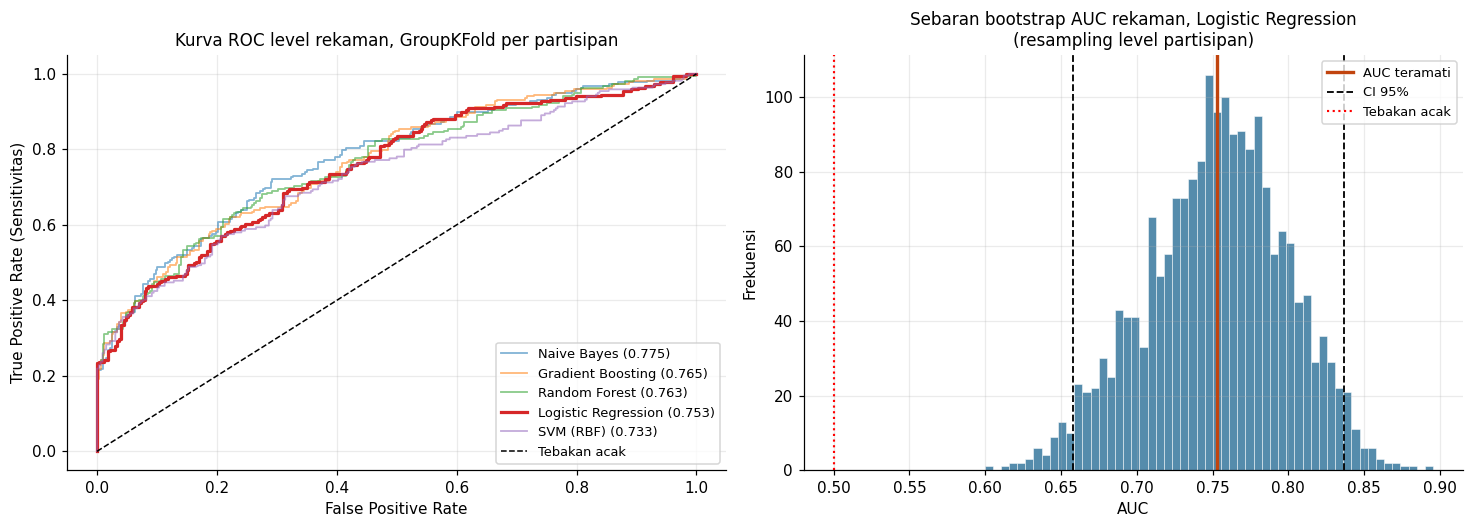

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.9))
ax = axes[0]
for name, pr in sorted(preds_grouped.items(), key=lambda kv: -roc_auc_score(y, kv[1])):
    ada = name == PRIMARY
    fpr_, tpr_, _ = roc_curve(y, pr)
    ax.plot(fpr_, tpr_, lw=2.1 if ada else 1.2, alpha=1.0 if ada else 0.55,
            label=f"{name} ({roc_auc_score(y, pr):.3f})")
ax.plot([0,1],[0,1],"k--",lw=1,label="Tebakan acak")
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate (Sensitivitas)")
ax.set_title("Kurva ROC level rekaman, GroupKFold per partisipan", fontsize=11)
ax.legend(fontsize=8.5, loc="lower right")

ax = axes[1]
ax.hist(b_dist, bins=55, color=C_TD, alpha=0.8, edgecolor="white", linewidth=0.4)
ax.axvline(roc_auc_score(y, primary_pred), color=C_ASD, lw=2.2, label="AUC teramati")
ax.axvline(b_lo, color="black", ls="--", lw=1.2, label="CI 95%"); ax.axvline(b_hi, color="black", ls="--", lw=1.2)
ax.axvline(0.5, color="red", ls=":", lw=1.4, label="Tebakan acak")
ax.set_xlabel("AUC"); ax.set_ylabel("Frekuensi")
ax.set_title(f"Sebaran bootstrap AUC rekaman, {PRIMARY}\n(resampling level partisipan)", fontsize=11)
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

### Memilih ambang untuk konteks skrining

Alat skrining punya asimetri biaya yang jelas:

- **False negative.** Anak ASD dinyatakan tidak berisiko, sehingga jendela intervensi dini hilang.
  Biayanya besar dan sering permanen.
- **False positive.** Anak TD dirujuk untuk pemeriksaan lanjutan, sehingga muncul kecemasan orang
  tua dan biaya asesmen tambahan. Tidak menyenangkan, tapi bisa dipulihkan.

Karena itu ambang dioptimalkan untuk **sensitivitas tinggi**, bukan akurasi keseluruhan.
Ambang dihitung pada **unit anak** dengan **model pra-tetap**, sesuai unit keputusan produk.

Model  : Logistic Regression (pra-tetap)
Unit   : anak (54 anak)
Ambang : 0.303 (dioptimalkan untuk sensitivitas >= 90%)

  Sensitivitas : 92.3%   <- anak ASD yang berhasil ditangkap
  Spesifisitas : 42.9%
  PPV          : 60.0%   <- pada prevalensi sampel 48%, bukan prevalensi lapangan
  NPV          : 85.7%

Pembanding Naive Bayes pada sensitivitas sama: spesifisitas 57.1%.
Selisih itu menunjukkan titik kerja belum stabil, jadi ambang produksi harus ditetapkan
bersama klinisi dari kapasitas rujukan, bukan diwarisi dari POC ini.

Pembanding M-CHAT di layanan primer: sensitivitas 49,2%, spesifisitas 94,2%, PPV 28,9%
Ini bukan perbandingan setara: beda populasi, beda kelompok usia, dan M-CHAT diuji
secara prospektif di lapangan. Disandingkan hanya untuk menunjukkan bahwa sinyal objektif
LAYAK DITELITI LEBIH LANJUT sebagai pelengkap ceklis, bukan sebagai klaim keunggulan.


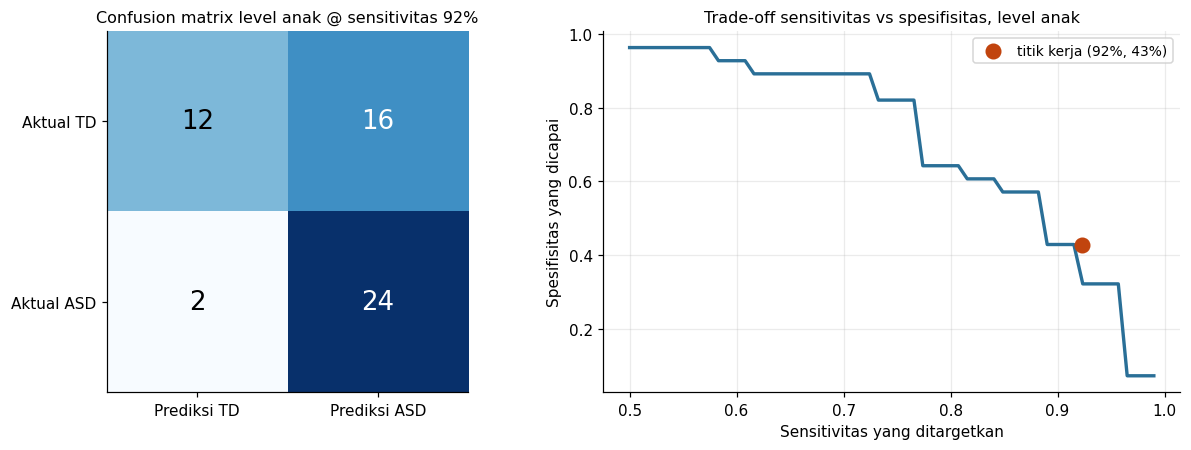

In [31]:
TARGET_SENS = 0.90
op = titik_kerja(p_prim, y_anak, TARGET_SENS)
chosen = op["threshold"]

pred_lab = (p_prim >= chosen).astype(int)
tn, fp, fn, tp = confusion_matrix(y_anak, pred_lab).ravel()
sens, spec = tp/(tp+fn), tn/(tn+fp)
ppv = tp/(tp+fp) if (tp+fp) else 0
npv = tn/(tn+fn) if (tn+fn) else 0

print(f"Model  : {PRIMARY} (pra-tetap)\nUnit   : anak ({len(y_anak)} anak)")
print(f"Ambang : {chosen:.3f} (dioptimalkan untuk sensitivitas >= {TARGET_SENS:.0%})\n")
print(f"  Sensitivitas : {sens:.1%}   <- anak ASD yang berhasil ditangkap")
print(f"  Spesifisitas : {spec:.1%}")
print(f"  PPV          : {ppv:.1%}   <- pada prevalensi sampel {y_anak.mean():.0%}, bukan prevalensi lapangan")
print(f"  NPV          : {npv:.1%}")
print(f"\nPembanding {BEST_RECORD} pada sensitivitas sama: spesifisitas {op_best_record['specificity']:.1%}.")
print("Selisih itu menunjukkan titik kerja belum stabil, jadi ambang produksi harus ditetapkan")
print("bersama klinisi dari kapasitas rujukan, bukan diwarisi dari POC ini.")
print(f"\nPembanding M-CHAT di layanan primer: sensitivitas 49,2%, spesifisitas 94,2%, PPV 28,9%")
print("Ini bukan perbandingan setara: beda populasi, beda kelompok usia, dan M-CHAT diuji")
print("secara prospektif di lapangan. Disandingkan hanya untuk menunjukkan bahwa sinyal objektif")
print("LAYAK DITELITI LEBIH LANJUT sebagai pelengkap ceklis, bukan sebagai klaim keunggulan.")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax = axes[0]
cm = np.array([[tn, fp],[fn, tp]])
im = ax.imshow(cm, cmap="Blues"); ax.grid(False)
for r in range(2):
    for c in range(2):
        ax.text(c, r, f"{cm[r,c]}", ha="center", va="center", fontsize=17,
                color="white" if cm[r,c] > cm.max()/2 else "black")
ax.set_xticks([0,1]); ax.set_xticklabels(["Prediksi TD","Prediksi ASD"])
ax.set_yticks([0,1]); ax.set_yticklabels(["Aktual TD","Aktual ASD"])
ax.set_title(f"Confusion matrix level anak @ sensitivitas {sens:.0%}", fontsize=10.5)

ax = axes[1]
fpr_a, tpr_a, thr_a = roc_curve(y_anak, p_prim)
sens_grid = np.linspace(0.5, 0.99, 60); spec_grid = []
for s in sens_grid:
    ok = np.flatnonzero(tpr_a >= s)
    spec_grid.append(1 - fpr_a[ok[np.argmin(fpr_a[ok])]])
ax.plot(sens_grid, spec_grid, lw=2.2, color=C_TD)
ax.scatter([sens],[spec], s=90, color=C_ASD, zorder=5, label=f"titik kerja ({sens:.0%}, {spec:.0%})")
ax.set_xlabel("Sensitivitas yang ditargetkan"); ax.set_ylabel("Spesifisitas yang dicapai")
ax.set_title("Trade-off sensitivitas vs spesifisitas, level anak", fontsize=10.5); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

## 6. Kurva belajar: apakah data lebih banyak akan membantu?

Kurva ini adalah diagnosis keterbatasan data, bukan dasar untuk menjanjikan kenaikan performa.
Untuk tiap ukuran, sebagian partisipan dipakai melatih model dan sisanya menjadi uji. Ketika jumlah
latih membesar, set uji mengecil sehingga varians estimasi ikut meningkat.

Hasil perlu dibaca dari kestabilan seluruh kurva dan kemiringan paruh akhir, bukan hanya selisih titik
awal dan akhir.


In [32]:
%%time
def learning_curve_by_participant(X, y, groups, sizes, n_rep=30, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    uniq = np.unique(groups)
    lab_of = {g: y[groups == g][0] for g in uniq}
    asd_p = np.array([g for g in uniq if lab_of[g] == 1])
    td_p  = np.array([g for g in uniq if lab_of[g] == 0])
    out = []
    for n in sizes:
        n_a = max(int(round(n*len(asd_p)/len(uniq))), 2)
        n_t = max(n - n_a, 2)
        if n_a >= len(asd_p) or n_t >= len(td_p): continue
        scores = []
        for _ in range(n_rep):
            tr = np.concatenate([rng.choice(asd_p, n_a, replace=False),
                                 rng.choice(td_p, n_t, replace=False)])
            te = np.setdiff1d(uniq, tr)
            m_tr, m_te = np.isin(groups, tr), np.isin(groups, te)
            if len(np.unique(y[m_te])) < 2: continue
            m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
            m.fit(X[m_tr], y[m_tr])
            scores.append(roc_auc_score(y[m_te], m.predict_proba(X[m_te])[:,1]))
        if scores:
            out.append({"n_participants": n, "mean": np.mean(scores), "std": np.std(scores),
                        "p25": np.percentile(scores,25), "p75": np.percentile(scores,75)})
    return pd.DataFrame(out)

sizes = [8, 12, 16, 20, 24, 28, 32, 36, 40, 44]
lc = learning_curve_by_participant(X, y, groups, sizes, n_rep=30)
display(lc.round(4))

,n_participants,mean,std,p25,p75
0,8,0.7289,0.0470,0.7205,0.7570
1,12,0.7381,0.0537,0.7209,0.7714
2,16,0.7534,0.0286,0.7329,0.7762
3,20,0.7632,0.0249,0.7429,0.7802
4,24,0.7682,0.0443,0.7337,0.7974
5,28,0.7721,0.0448,0.7454,0.8134
6,32,0.7808,0.0509,0.7503,0.8196
7,36,0.7413,0.0497,0.7280,0.7767
8,40,0.7682,0.0700,0.7398,0.8148
9,44,0.7662,0.1017,0.6976,0.8353


CPU times: user 1.12 s, sys: 17.6 ms, total: 1.14 s
Wall time: 1.14 s


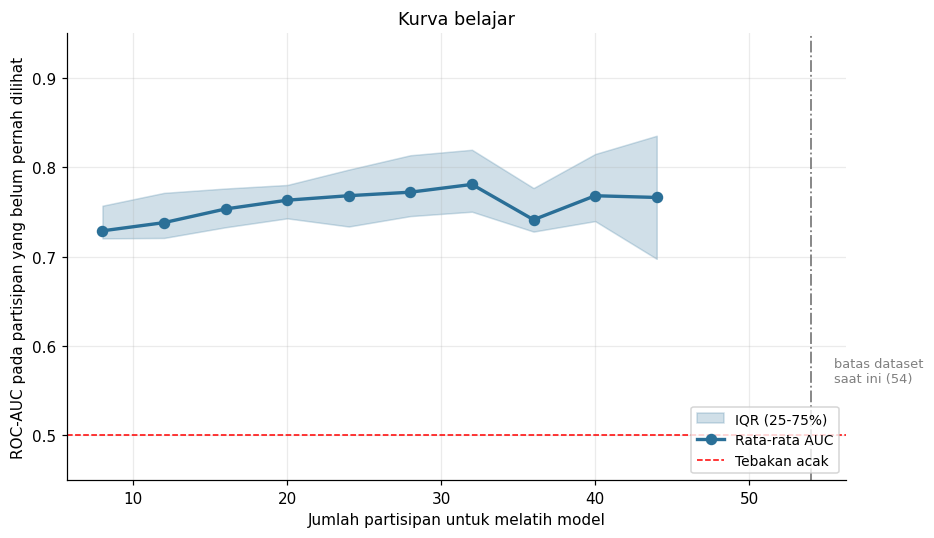

AUC pada 8 partisipan  : 0.729
AUC pada 44 partisipan : 0.766
Kenaikan keseluruhan: +0.037 AUC

Kemiringan paruh awal  (per log-partisipan): +0.0379
Kemiringan paruh akhir (per log-partisipan): -0.0238

=> Paruh akhir menurun/tidak stabil. Data ini BELUM dapat menentukan batas atas
   performa atau membuktikan bahwa tambahan data otomatis meningkatkan AUC.

Tidak ada ekstrapolasi performa di luar ukuran dataset yang diamati.


In [33]:
fig, ax = plt.subplots(figsize=(8.6, 5))
ax.fill_between(lc.n_participants, lc.p25, lc.p75, alpha=0.22, color=C_TD, label="IQR (25-75%)")
ax.plot(lc.n_participants, lc["mean"], "o-", color=C_TD, lw=2.2, ms=6.5, label="Rata-rata AUC")
ax.axhline(0.5, color="red", ls="--", lw=1, label="Tebakan acak")
ax.axvline(len(np.unique(groups)), color="grey", ls="-.", lw=1.2)
ax.text(len(np.unique(groups))+1.5, 0.56, f"batas dataset\nsaat ini ({len(np.unique(groups))})",
        fontsize=8.5, color="grey")
ax.set_xlabel("Jumlah partisipan untuk melatih model")
ax.set_ylabel("ROC-AUC pada partisipan yang belum pernah dilihat")
ax.set_title("Kurva belajar", fontsize=11.5); ax.legend(fontsize=9, loc="lower right")
ax.set_ylim(0.45, 0.95)
plt.tight_layout(); plt.show()

g0, g1 = lc["mean"].iloc[0], lc["mean"].iloc[-1]
print(f"AUC pada {lc.n_participants.iloc[0]} partisipan  : {g0:.3f}")
print(f"AUC pada {lc.n_participants.iloc[-1]} partisipan : {g1:.3f}")
print(f"Kenaikan keseluruhan: {g1-g0:+.3f} AUC\n")

half = len(lc)//2
slope_awal  = np.polyfit(np.log(lc.n_participants[:half]), lc["mean"][:half], 1)[0]
slope_akhir = np.polyfit(np.log(lc.n_participants[half:]), lc["mean"][half:], 1)[0]
print(f"Kemiringan paruh awal  (per log-partisipan): {slope_awal:+.4f}")
print(f"Kemiringan paruh akhir (per log-partisipan): {slope_akhir:+.4f}")

if slope_akhir > 0.01:
    print("\n=> Paruh akhir masih naik, tetapi kesimpulan tetap tentatif karena set uji mengecil.")
elif slope_akhir > 0:
    print("\n=> Paruh akhir sedikit naik dan belum cukup stabil untuk ekstrapolasi.")
else:
    print("\n=> Paruh akhir menurun/tidak stabil. Data ini BELUM dapat menentukan batas atas")
    print("   performa atau membuktikan bahwa tambahan data otomatis meningkatkan AUC.")

print("\nTidak ada ekstrapolasi performa di luar ukuran dataset yang diamati.")

## 7. Fitur mana yang menggerakkan keputusan model

Untuk alat kesehatan, "kenapa" sama pentingnya dengan "berapa". Kami pakai **permutation importance**
di bawah protokol group-aware: acak satu fitur, lihat seberapa jauh AUC jatuh.

In [34]:
%%time
def group_permutation_importance(X, y, groups, features, n_rep=12, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    cv = GroupKFold(n_splits=5)
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))
    base = roc_auc_score(y, cross_val_predict(m, X, y, cv=cv, groups=groups, method="predict_proba")[:,1])
    rows = []
    for j, f in enumerate(features):
        drops = []
        for _ in range(n_rep):
            Xp = X.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
            a = roc_auc_score(y, cross_val_predict(m, Xp, y, cv=cv, groups=groups,
                                                   method="predict_proba")[:,1])
            drops.append(base - a)
        rows.append({"feature": f, "importance": np.mean(drops), "std": np.std(drops)})
    return base, pd.DataFrame(rows).sort_values("importance", ascending=False)

base_auc, imp = group_permutation_importance(X, y, groups, FEATURES)
print(f"AUC baseline: {base_auc:.4f}\n")
display(imp.head(10).round(4))

AUC baseline: 0.7531



,feature,importance,std
0,ink_frac,0.0115,0.0045
5,span_x,0.0030,0.0025
8,radial_std,0.0029,0.0014
7,radial_mean,0.0009,0.0023
6,span_y,0.0008,0.0012
3,std_x,0.0007,0.0044
15,grid_entropy,0.0006,0.0021
16,n_active_cells,-0.0011,0.0030
17,bbox_fill,-0.0012,0.0023
1,centroid_x,-0.0012,0.0029


CPU times: user 3.84 s, sys: 74 ms, total: 3.91 s
Wall time: 3.96 s


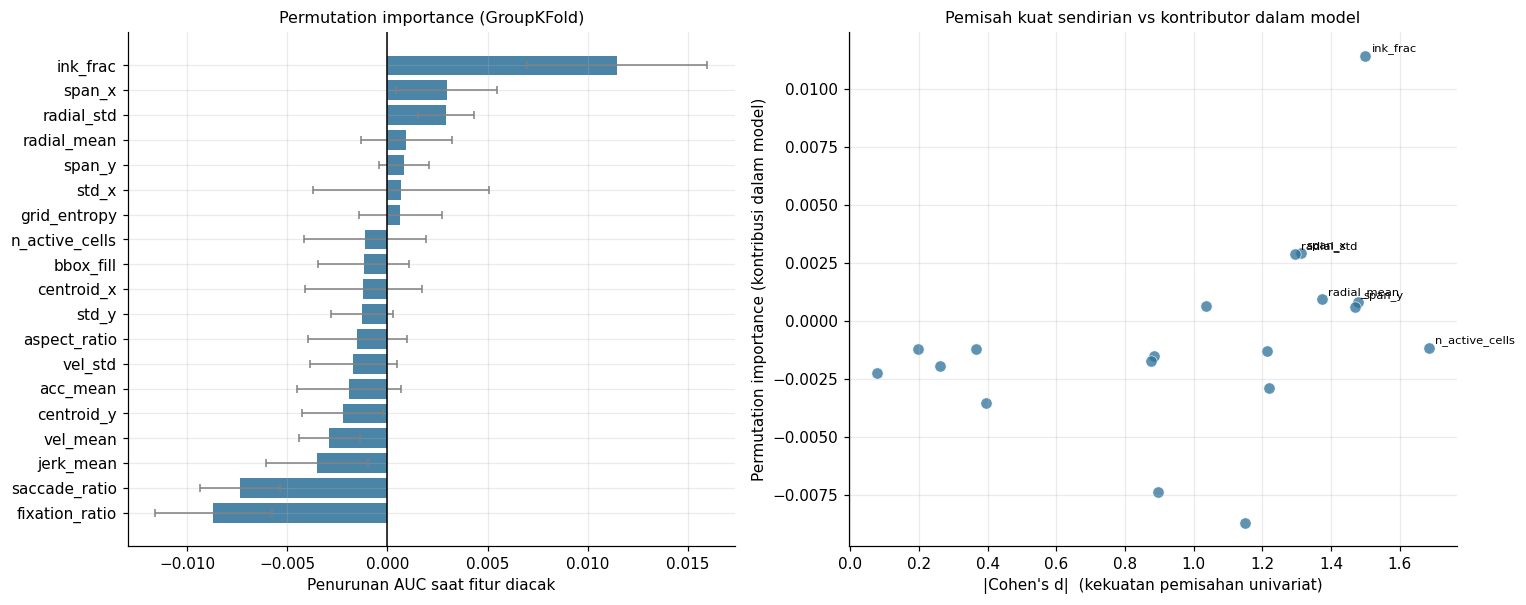

Catatan: Carette dkk. mencatat partisipan ASD cenderung melihat ke BAGIAN BAWAH layar,
   tempat perangkat eye-tracker diletakkan. Kalau 'centroid_y' penting, itu bisa
   jadi artefak penempatan alat, bukan perilaku ASD murni.

-> Peringkat 'centroid_y': 15 dari 19


In [35]:
t = imp.iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
ax = axes[0]
ax.barh(t.feature, t.importance, xerr=t["std"], color=C_TD, alpha=0.85,
        error_kw=dict(lw=1, capsize=2.5, ecolor="grey"))
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Penurunan AUC saat fitur diacak")
ax.set_title("Permutation importance (GroupKFold)", fontsize=10.5)

ax = axes[1]
mg = imp.set_index("feature").join(eff[["cohens_d"]])
ax.scatter(mg.cohens_d.abs(), mg.importance, s=55, color=C_TD, alpha=0.75,
           edgecolor="white", linewidth=0.5)
for f_, r_ in mg.iterrows():
    if r_.importance > mg.importance.quantile(0.75) or abs(r_.cohens_d) > mg.cohens_d.abs().quantile(0.85):
        ax.annotate(f_, (abs(r_.cohens_d), r_.importance), fontsize=7.5,
                    xytext=(4,3), textcoords="offset points")
ax.set_xlabel("|Cohen's d|  (kekuatan pemisahan univariat)")
ax.set_ylabel("Permutation importance (kontribusi dalam model)")
ax.set_title("Pemisah kuat sendirian vs kontributor dalam model", fontsize=10.5)
plt.tight_layout(); plt.show()

cy_rank = imp.reset_index(drop=True).query("feature == 'centroid_y'").index
print("Catatan: Carette dkk. mencatat partisipan ASD cenderung melihat ke BAGIAN BAWAH layar,")
print("   tempat perangkat eye-tracker diletakkan. Kalau 'centroid_y' penting, itu bisa")
print("   jadi artefak penempatan alat, bukan perilaku ASD murni.")
print(f"\n-> Peringkat 'centroid_y': {(cy_rank[0]+1) if len(cy_rank) else 'n/a'} dari {len(FEATURES)}")

## 8. Kesimpulan POC Cabang Pandangan

### Yang berhasil ditunjukkan

1. **Sinyalnya nyata dan bisa dijelaskan.** Fitur geometri bermakna fisik memisahkan ASD dari TD
   di bawah evaluasi yang dikelompokkan per partisipan.
2. **Protokol evaluasi mengubah angka.** Pada reimplementasi ini, dengan regresi logistik dan 19
   fitur yang identik di seluruh protokol, penggelembungan total 0,063 AUC terurai menjadi
   0,019 dari kebocoran antarsalinan augmentasi dan 0,048 dari tidak mengelompokkan data per
   anak. Sumber terbesarnya pengelompokan, bukan augmentasi; augmentasi ketika split sudah
   benar justru menurunkan AUC 0,005. Angka ini berlaku untuk konfigurasi kami, bukan koreksi
   yang dapat dikurangkan dari hasil orang lain.
3. **Unit metrik penting, dan model dipilih pada unit yang benar.** Endpoint utama adalah AUC
   level anak pada model pra-tetap (regresi logistik): 0,845 dengan CI 95% 0,730-0,944 pada 54
   anak, dibandingkan 0,753 pada level rekaman. Naive Bayes memperoleh AUC rekaman tertinggi
   0,775 tetapi pada level anak hanya 0,834, dan random forest yang tertinggi pada level anak
   (0,864) tidak pernah terpilih di nested GroupKFold. Peringkat antar model belum stabil,
   sehingga POC ini tidak menetapkan model produksi.
4. **Komputasinya ringan.** Ekstraksi fitur tidak membutuhkan GPU atau deep learning.
5. **Batas atas performa belum diketahui.** Kurva belajar berfluktuasi dan menurun pada paruh
   akhir; data yang ada tidak membuktikan bahwa menambah sampel otomatis menaikkan AUC.

### Limitasi yang dinyatakan terbuka

| Limitasi | Dampak | Rencana mitigasi |
|---|---|---|
| Hanya 54 partisipan | CI lebar, generalisasi terbatas | Kohort prospektif terkelompok per anak, memuat kontrol negatif sulit non-autisme |
| Usia 7,88 tahun, bukan balita | Tidak memvalidasi skrining dini | Validasi pada usia 16-30 bulan, target populasi produk |
| Eye-tracker lab, bukan webcam | Rantai piksel kamera ke titik pandang belum diuji | Studi jembatan pada subjek sama dengan kriteria go/no-go |
| Partisipan Prancis | Norma budaya berbeda | Stimulus dan kalibrasi Indonesia |
| Spesifisitas 42,9% pada sensitivitas 92,3% (model pra-tetap) | Pada prevalensi 1% PPV hanya 1,6%, sekitar 62 rujukan per satu kasus benar | Ambang ditetapkan dari kapasitas rujukan, bukan dari POC |
| Titik kerja tidak stabil antar model | Naive Bayes mencapai spesifisitas 57,1% pada sensitivitas sama | Kalibrasi dan penetapan ambang pada kohort prospektif |
| Potensi bias posisi alat | Fitur vertikal dapat menjadi artefak | Randomisasi penempatan |

### Posisi terhadap produk multimodal

POC ini hanya menjadi bukti empiris **cabang pandangan**. Cabang kepala/wajah, vokalisasi,
dan weighted late fusion adalah rancangan produk prospektif. Tidak ada metrik fusion yang
dilaporkan sampai tersedia probabilitas out-of-fold terkalibrasi dari anak dan sesi yang sama.


In [36]:
out = {
    "evidence_scope": "gaze_only",
    "product_modalities": ["gaze", "head_face", "vocalization"],
    "fusion_method": "quality_aware_weighted_late_fusion",
    "fusion_status": "prospective_paired_validation_required",
    "decision_unit": "child",
    "n_citra": len(meta),
    "n_partisipan": int(meta.participant.nunique()),
    "n_fitur": len(FEATURES),
    "n_anak_asd": int(y_anak.sum()),
    "n_anak_td": int(len(y_anak) - y_anak.sum()),
    "model_pra_tetap": PRIMARY,
    "model_auc_rekaman_tertinggi": BEST_RECORD,
    "model_auc_anak_tertinggi": BEST_CHILD,
    "auc_record_level": {k: round(float(v), 4) for k, v in auc_record_level.items()},
    "auc_child_level": {k: round(float(v), 4) for k, v in auc_child_level.items()},
    "auc_child_primary": round(float(auc_child_level[PRIMARY]), 4),
    "ci95_child_primary": [round(float(lo_a), 4), round(float(hi_a), 4)],
    "auc_record_primary": round(float(auc_record_level[PRIMARY]), 4),
    "auc_child_best_record_model": round(float(auc_child_level[BEST_RECORD]), 4),
    "auc_record_best": round(float(auc_record_level[BEST_RECORD]), 4),
    "nested_auc_record": round(float(nested_auc_record), 4),
    "nested_auc_child": round(float(nested_auc_child), 4),
    "nested_ci95_child": [round(float(lo_n), 4), round(float(hi_n), 4)],
    "nested_model_per_fold": terpilih,
    "titik_kerja_anak_primary": {k: round(float(v), 4) for k, v in op_primary.items()},
    "titik_kerja_anak_best_record_model": {k: round(float(v), 4) for k, v in op_best_record.items()},
    "varians_antarpartisipan": round(float(icc.mean()), 4),
    "cohens_d_teratas": {k: round(float(v), 3) for k, v in eff.cohens_d.head(5).items()},
    "fitur_teratas": imp.head(5).feature.tolist(),
    "protokol": {
        "A_augmentasi_split_acak": round(float(auc_A), 4),
        "B_augmentasi_group_citra_sumber": round(float(auc_B), 4),
        "C_augmentasi_group_partisipan": round(float(auc_C), 4),
        "D_tanpa_augmentasi_group_partisipan": round(float(auc_D), 4),
    },
    "dekomposisi": {
        "kebocoran_salinan_augmentasi_A_B": round(float(auc_A - auc_B), 4),
        "tanpa_grouping_partisipan_B_C": round(float(auc_B - auc_C), 4),
        "efek_augmentasi_split_benar_C_D": round(float(auc_C - auc_D), 4),
        "total_A_D": round(float(auc_A - auc_D), 4),
    },
    "lc_auc_awal": round(float(g0), 4),
    "lc_auc_akhir": round(float(g1), 4),
    "lc_slope_paruh_akhir": round(float(slope_akhir), 4),
}

# PPV pada prevalensi hipotetis, memakai titik kerja model pra-tetap
for prev, tag in ((0.01, "1persen"), (0.02, "2persen")):
    s_, sp_ = op_primary["sensitivity"], op_primary["specificity"]
    ppv_prev = s_*prev / (s_*prev + (1-sp_)*(1-prev))
    out[f"ppv_prevalensi_{tag}"] = round(float(ppv_prev), 4)
    out[f"rujukan_per_kasus_prevalensi_{tag}"] = round(float(1/ppv_prev), 1)

print("="*64); print("ANGKA UNTUK CONCEPT PAPER"); print("="*64)
for k, v in out.items(): print(f"{k:38s} : {v}")
print("="*64)

import json
with open("poc_hasil.json", "w") as fh:
    json.dump(out, fh, indent=2, ensure_ascii=False)
print("\nDisimpan ke poc_hasil.json")

ANGKA UNTUK CONCEPT PAPER
evidence_scope                         : gaze_only
product_modalities                     : ['gaze', 'head_face', 'vocalization']
fusion_method                          : quality_aware_weighted_late_fusion
fusion_status                          : prospective_paired_validation_required
decision_unit                          : child
n_citra                                : 547
n_partisipan                           : 54
n_fitur                                : 19
n_anak_asd                             : 26
n_anak_td                              : 28
model_pra_tetap                        : Logistic Regression
model_auc_rekaman_tertinggi            : Naive Bayes
model_auc_anak_tertinggi               : Random Forest
auc_record_level                       : {'Logistic Regression': 0.7531, 'SVM (RBF)': 0.7333, 'Naive Bayes': 0.7753, 'Random Forest': 0.7627, 'Gradient Boosting': 0.7655}
auc_child_level                        : {'Logistic Regression': 0.8448, 'SVM (R

## 9. Arsitektur Multimodal dan Late Fusion

TATAP memakai tiga model unimodal terpisah pada satu sesi dua menit:

| Cabang | Masukan | Contoh fitur | Status bukti |
|---|---|---|---|
| Pandangan | Kamera depan | cakupan, dispersi, fiksasi, entropi | POC empiris tersedia |
| Kepala/wajah | Kamera depan | orientasi, stabilitas, respons nama | Prospektif |
| Vokalisasi | Mikrofon | latensi, energi, jeda, prosodi | Prospektif |

Kontrol kualitas berlapis dan penempatannya penting. Pada perekaman hanya ada *capture QC*,
yaitu pemeriksaan yang dapat dilakukan sebelum pemodelan: kamera dan mikrofon berfungsi, wajah
tertangkap, dan pencahayaan memadai. Skor kualitas $q_m$ dan kalibrasi probabilitas berada di
dalam masing-masing cabang, sebab keduanya baru dapat dihitung setelah modalitasnya diproses.
Yang mengalir ke fusi adalah pasangan $(p_m, q_m)$ per modalitas.

Model boleh dipralatih pada kohort berbeda. Namun probabilitas tidak boleh dipasangkan antar
subjek untuk menguji fusion. Kalibrasi dan evaluasi akhir wajib memakai modalitas dari anak dan
sesi yang sama.


In [37]:
# Kontrak implementasi fusion; ini bukan eksperimen performa multimodal.
import sys

PROJECT_DIR = DATA_DIR.parent.parent
if str(PROJECT_DIR / "research") not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR / "research"))

from late_fusion import fuse_probabilities, learn_nonnegative_weights

fusion_components = pd.DataFrame([
    {"modality": "gaze", "model": "interpretable scanpath features", "status": "POC validated"},
    {"modality": "head_face", "model": "lightweight motion features", "status": "prospective"},
    {"modality": "vocalization", "model": "lightweight audio features", "status": "prospective"},
])
display(fusion_components)


,modality,model,status
0,gaze,interpretable scanpath features,POC validated
1,head_face,lightweight motion features,prospective
2,vocalization,lightweight audio features,prospective


### Audit dataset multimodal kedua

Dataset kedua berisi 100 sampel gambar, suara, gerak, dan fisiologi sintetis. Audit sebelumnya
menemukan fitur lintas label nyaris identik serta pemetaan nama berkas gambar tidak cocok dengan
indeks. Karena itu dataset ini hanya boleh dipakai untuk memeriksa skema dan integrasi perangkat
lunak, bukan melatih komponen prediktif atau menghasilkan metrik lomba.


In [38]:
MM_DIR = PROJECT_DIR / "data" / "Multimodal Autism Dataset"
mm_index = pd.read_csv(MM_DIR / "autism_dataset_index.csv")

display(mm_index.label.value_counts().rename_axis("label").to_frame("n"))
print("Jumlah sampel:", len(mm_index))
print("Kebijakan: schema/integration smoke-test only; tidak ada klaim performa.")


,n
label,
severe_asd,33
typical,25
mild_asd,23
moderate_asd,19


Jumlah sampel: 100
Kebijakan: schema/integration smoke-test only; tidak ada klaim performa.


### Quality-aware weighted late fusion

Setiap model menghasilkan probabilitas ASD terkalibrasi $p_m$ dan skor kualitas $q_m$.
Prediksi akhir memakai $p=\sum_m \alpha_m p_m$, dengan $\alpha_m$ sebanding dengan bobot
nonnegatif $w_m$ dikali kualitas $q_m$. Modalitas yang hilang atau di bawah ambang kualitas
dikeluarkan, lalu bobot yang tersisa dinormalisasi ulang.

**Aturan abstain (keputusan produk).** Sistem tidak mengeluarkan skor dan meminta sesi diulang
bila cabang pandangan gagal ambang kualitas, atau bila kurang dari dua modalitas lolos ambang.
Layar penahanan menyebut modalitas yang gagal beserta angkanya, sehingga kader dapat
memperbaiki kondisi perekaman. Penahanan bukan pernyataan bahwa anak normal.

Perlu dibedakan dua hal yang tampak mirip. **Kegagalan perekaman**, misalnya wajah tidak
terlihat atau mikrofon tertutup, menurunkan $q_m$ sehingga modalitasnya dikeluarkan.
**Ketiadaan respons pada rekaman berkualitas baik**, misalnya anak tidak menoleh saat namanya
dipanggil, justru dipertahankan sebagai fitur perilaku. Menyamakan keduanya membuang sinyal
klinis yang paling informatif.

Sel berikut hanya smoke test deterministik untuk memverifikasi perilaku fungsi. Angkanya adalah
contoh buatan dan **bukan hasil dataset**.


In [39]:
demo_probabilities = {
    "gaze": np.array([0.20, 0.80]),
    "head_face": np.array([0.40, 0.60]),
    "vocalization": np.array([np.nan, 0.10]),
}
demo_quality = {
    "gaze": np.array([1.00, 1.00]),
    "head_face": np.array([0.90, 0.90]),
    "vocalization": np.array([1.00, 0.20]),
}
demo_weights = {"gaze": 2.0, "head_face": 1.0, "vocalization": 1.0}

demo_fused = fuse_probabilities(
    demo_probabilities,
    demo_weights,
    quality=demo_quality,
    minimum_quality=0.50,
)
display(pd.DataFrame({
    "p_fused_demo": demo_fused.probability,
    "n_modalitas_usable": demo_fused.available_modalities,
}))
assert demo_fused.available_modalities.tolist() == [2, 2]
print("Smoke test fusion lulus. Angka di atas bukan metrik performa.")


,p_fused_demo,n_modalitas_usable
0,0.262069,2
1,0.737931,2


Smoke test fusion lulus. Angka di atas bukan metrik performa.


### Protokol validasi prospektif

1. Rekam seluruh modalitas dari anak dan sesi yang sama. Acuannya adalah asesmen perkembangan
   terstandar dan diagnosis konsensus oleh klinisi yang **dibutakan terhadap keluaran TATAP**;
   instrumennya disepakati sebelum pengumpulan data, dan kasus yang belum pasti dipantau ulang,
   bukan dipaksa masuk salah satu kelas.
2. Bentuk prediksi out-of-fold memakai split terkelompok per anak. Seluruh kunjungan dari anak
   yang sama (18 dan 24 bulan) wajib berada pada lipatan yang sama, dan satu lokasi layanan
   disisihkan penuh sebagai validasi eksternal.
3. Kalibrasi probabilitas dan pembelajaran bobot **hanya dilakukan di lipatan dalam** yang
   dikelompokkan per anak, memakai constrained logistic stacking berpenalti. Anak dan lokasi
   pada lipatan luar tidak pernah ikut mengkalibrasi; tanpa pemisahan ini, kenaikan yang tampak
   dari fusi dapat berasal dari kebocoran kalibrasi.
4. Bandingkan model unimodal terbaik, rata-rata sama bobot, dan bobot nonnegatif yang dipelajari.
5. Nilai ROC-AUC, Brier score/kurva kalibrasi, sensitivitas-spesifisitas, kegagalan rekaman, dan
   beban rujukan. Metrik per subkelompok hanya dinilai bila subkelompok memuat minimal 30 anak
   dan 8 kasus terkonfirmasi.
6. Terima fusion hanya jika mengungguli model unimodal terbaik dan memperbaiki kalibrasi pada
   held-out participants sekaligus lokasi held-out.

Dengan demikian notebook dan concept paper selaras: **produk bersifat multimodal, sedangkan
bukti empiris yang tersedia saat ini tetap gaze-only**.
